# B · ENASIC 2022: necesidad, barreras y perfil de las personas cuidadoras

Microdatos ENASIC 2022 con diseño muestral: por qué no se usan servicios, necesidad vs. norma, segmentación, perfil del grupo y modelo de focalización.

Este notebook junta varios análisis que antes estaban separados. Cada sección conserva su **número original** y escribe los mismos archivos en `resultados/`, con el mismo prefijo. Una cifra citada como "notebook 04" se rastrea a la sección 04.

| Sección | Tema | Archivo original | Escribe |
|---|---|---|---|
| [03](#s03) | Barreras de uso de servicios de cuidado | `03_enasic_barreras_uso_servicios.ipynb` | `resultados/03_*` |
| [07](#s07) | "No tuvo necesidad": ¿ausencia o carga normalizada? | `07_enasic_necesidad_vs_norma.ipynb` | `resultados/07_*` |
| [12](#s12) | Indicadores del Observatorio por segmento | `12_enasic_segmentacion_observatorio.ipynb` | `resultados/12_*` |
| [16](#s16) | Perfil del grupo del problema y horas de cuidado | `16_enasic_perfil_grupo_horas.ipynb` | `resultados/16_*` |
| [11](#s11) | Modelo de focalización (logit) | `11_modelo_focalizacion_cuidadoras.ipynb` | `resultados/11_*` |

Requiere los microdatos en `Analysis/datos/enasic/`. La sección 07 lee `resultados/04_contratacion_por_quintil.csv`, que genera la sección 04 del notebook C.

Cada sección carga sus datos desde cero, así que no dependen de variables de secciones anteriores. Ejecutar con *Kernel → Restart & Run All* desde la carpeta `Analysis/`.

<a id="s03"></a>

---

*Sección 03 · antes `03_enasic_barreras_uso_servicios.ipynb`*

# 03 — ENASIC 2022 (microdatos): ¿por qué no se usan servicios de cuidado?

**Para qué decisión existe este notebook.** El programa candidato es una app que conecte "Necesito cuidado" con "Puedo cuidar". Solo se justifica si la barrera principal es de **conexión**: no saber que existen servicios, o desconfiar de desconocidos. Si la barrera es el **precio**, se necesita un subsidio. Si es la **preferencia por el cuidado familiar**, ningún servicio la resuelve.
La ENASIC es la única fuente que tenemos que pregunta por eso directamente (P6.42–P6.48).

**Alcance.** Nacional. La ENASIC **no** permite estimaciones para la CDMX ni por alcaldía. Nada de lo que sale de aquí se puede presentar como dato de Iztapalapa.

**Método.** Estimaciones ponderadas con el factor de expansión de cada tabla. Varianza por linealización de Taylor con estratos `EST_DIS` y conglomerados `UPM_DIS`: es el mismo diseño que usa el código en R del INEGI. Se aplican los criterios de precisión del INEGI según el coeficiente de variación:
- alta: CV < 15%
- moderada: 15% ≤ CV < 30%
- baja: CV ≥ 30%. Las estimaciones de precisión baja no se usan como hallazgo.

**Universos.** Una misma persona puede estar en varias tablas, así que las tablas **no se suman entre sí**:
- `TPOB_CUI`: personas cuidadoras de 15 años y más. Factor `FAC_CUI`.
- `TPER_ELE`: persona elegida de 15 a 60 años. Factor `FAC_ELE`.
- `THOGAR`: hogares. Factor `FAC_HOG`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 80)

BASE = Path('datos/enasic')
OUT = Path('resultados'); OUT.mkdir(exist_ok=True)

def tabla(nombre, archivo=None):
    archivo = archivo or f'conjunto_de_datos_{nombre}_enasic_2022.csv'
    df = pd.read_csv(BASE / f'conjunto_de_datos_{nombre}_enasic_2022' / 'conjunto_de_datos' / archivo, dtype=str)
    return df

cui = tabla('tpob_cui'); ele = tabla('tper_ele')
hog = tabla('thogar', 'conjunto_de_datos_thogar_ensasic_2022.csv')   # así viene el nombre (typo del INEGI)
sde = tabla('tcsdempo')
for n, d in [('TPOB_CUI', cui), ('TPER_ELE', ele), ('THOGAR', hog), ('TCSDEMPO', sde)]:
    print(f'{n:9s} registros={len(d):6d}  estratos={d.EST_DIS.nunique()}  UPM={d.UPM_DIS.nunique()}')

TPOB_CUI  registros=  5677  estratos=148  UPM=861
TPER_ELE  registros=  5579  estratos=148  UPM=895
THOGAR    registros=  6508  estratos=148  UPM=896
TCSDEMPO  registros= 21776  estratos=148  UPM=896


## 1. Función de estimación con diseño muestral

Estima una **proporción** (un cociente de totales ponderados) junto con su error estándar, su coeficiente de variación y su intervalo de confianza al 90%, que es el nivel que usa el INEGI.
Los estratos con una sola UPM no aportan a la varianza. El número de estratos en esa situación se reporta.

In [2]:
Z90 = 1.6449

def estimar(df, y, x, peso, etiqueta=''):
    """Proporción ponderada R = Σw·y / Σw·x con varianza por linealización de Taylor.
    y, x: arrays 0/1 (numerador y dominio). Solo cuentan los registros con x = 1."""
    w = pd.to_numeric(df[peso]).to_numpy(float)
    y = np.asarray(y, float); x = np.asarray(x, float)
    X = (w * x).sum(); Y = (w * y).sum(); R = Y / X
    z = w * (y - R * x) / X
    t = pd.DataFrame({'h': df.EST_DIS.values, 'u': df.UPM_DIS.values, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z
    n_h = g.transform('size'); zbar = g.transform('mean')
    var = ((n_h / (n_h - 1)).where(n_h > 1, 0) * (t.z - zbar) ** 2).sum()
    se = np.sqrt(var); cv = se / R * 100 if R > 0 else np.nan
    prec = 'alta' if cv < 15 else ('moderada' if cv < 30 else 'baja')
    return dict(indicador=etiqueta, pct=R * 100, se=se * 100, cv=cv, li90=(R - Z90 * se) * 100, ls90=(R + Z90 * se) * 100,
                n_muestra_dominio=int(x.sum()), n_muestra_si=int((y * x).sum()), total_expandido=Y, precision=prec)

def es(df, col, val='1'):
    return (df[col] == val).astype(int).to_numpy()

def tab(filas):
    return pd.DataFrame(filas).round({'pct': 1, 'se': 2, 'cv': 1, 'li90': 1, 'ls90': 1, 'total_expandido': 0})

### 1.1 Validación contra cifras publicadas por el INEGI

Si la función reproduce lo que publicó el INEGI, se puede confiar en ella para el resto del análisis:
- Participación en cuidados de la población de 15 años y más: **32.0%**, que son **31.7 millones** de personas. Se calcula en TCSDEMPO con `P4_69_i` y `FAC_HOG`, siguiendo la guía *Conociendo la base de datos*.
- Hogares que contratan personal de enfermería o de cuidados: **0.8%**. Comunicado 578/23, p. 14.

In [3]:
sde['EDAD_N'] = pd.to_numeric(sde.EDAD, errors='coerce')
cuida = sde[[f'P4_69_{i}' for i in range(1, 7)]].isin(['1', '9']).any(axis=1).astype(int).to_numpy()
p15 = sde.EDAD_N.between(15, 98).astype(int).to_numpy()
v1 = estimar(sde, cuida * p15, p15, 'FAC_HOG', 'Población 15+ que brinda cuidados (publicado: 32.0%, 31.7 M)')

enf_o_cui = ((hog.P2_4_3 == '1') | (hog.P2_4_4 == '1')).astype(int).to_numpy()
v2 = estimar(hog, enf_o_cui, np.ones(len(hog)), 'FAC_HOG', 'Hogares que contratan enfermería o cuidadoras (publicado: 0.8%)')
val = tab([v1, v2]); val

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,"Población 15+ que brinda cuidados (publicado: 32.0%, 31.7 M)",32.0,0.51,1.6,31.2,32.8,16590,5758,31652134.0,alta
1,Hogares que contratan enfermería o cuidadoras (publicado: 0.8%),0.7,0.12,18.2,0.5,0.9,6508,45,265054.0,moderada


## 2. ¿Buscan servicios de cuidado? ¿Por qué no?

**Universo principal.** Cuidadoras y cuidadores (TPOB_CUI) de una persona del hogar **con discapacidad** (`FILTRO6_1`) o **de 60 años y más** (`FILTRO6_6`). Es la población objetivo del programa.
- **P6.42:** desde octubre de 2021, ¿buscó directamente una guardería, casa del abuelo o asilo?
- **P6.45:** a quien no buscó, ¿por qué no buscó? Es de respuesta múltiple, así que los porcentajes no suman 100.

In [4]:
RAZONES_NO_BUSCA = {
 'P6_45_01': 'El propio hogar cuida', 'P6_45_02': 'Apoyan otros hogares/familiares/conocidos',
 'P6_45_03': 'Son caros', 'P6_45_04': 'Preocupa el qué dirán', 'P6_45_05': 'DESCONOCE QUE EXISTEN',
 'P6_45_06': 'Incomodidad/desconfianza de que alguien ajeno cuide', 'P6_45_07': 'Lejanía',
 'P6_45_08': 'Maltrato del personal', 'P6_45_09': 'No ha tenido necesidad', 'P6_45_10': 'Otra razón'}

def bloque_busqueda(df, dominio, peso, nombre):
    filas = [estimar(df, es(df, 'P6_42') * dominio, dominio, peso, f'{nombre} | Buscó servicio (P6.42)')]
    no_busco = dominio * es(df, 'P6_42', '2')
    for col, et in RAZONES_NO_BUSCA.items():
        filas.append(estimar(df, es(df, col) * no_busco, no_busco, peso, f'{nombre} | No buscó por: {et}'))
    return filas

dom_obj = ((cui.FILTRO6_1 == '1') | (cui.FILTRO6_6 == '1')).astype(int).to_numpy()
dom_todos = np.ones(len(cui), int)
b_obj = tab(bloque_busqueda(cui, dom_obj, 'FAC_CUI', 'Cuidan discapacidad o 60+'))
b_obj.sort_values('pct', ascending=False)

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
9,Cuidan discapacidad o 60+ | No buscó por: No ha tenido necesidad,49.4,3.30,6.7,44.0,54.8,1019,556,2997224.0,alta
1,Cuidan discapacidad o 60+ | No buscó por: El propio hogar cuida,41.9,3.93,9.4,35.5,48.4,1019,373,2544153.0,alta
2,Cuidan discapacidad o 60+ | No buscó por: Apoyan otros hogares/familiares/co...,6.2,1.14,18.5,4.3,8.0,1019,64,373994.0,moderada
10,Cuidan discapacidad o 60+ | No buscó por: Otra razón,3.2,0.75,23.4,2.0,4.4,1019,35,194990.0,moderada
7,Cuidan discapacidad o 60+ | No buscó por: Lejanía,3.0,0.79,26.5,1.7,4.3,1019,26,179905.0,moderada
3,Cuidan discapacidad o 60+ | No buscó por: Son caros,2.8,0.66,23.5,1.7,3.9,1019,34,170769.0,moderada
0,Cuidan discapacidad o 60+ | Buscó servicio (P6.42),2.5,0.76,30.5,1.2,3.7,1043,24,154125.0,baja
5,Cuidan discapacidad o 60+ | No buscó por: DESCONOCE QUE EXISTEN,1.6,0.62,38.0,0.6,2.6,1019,16,98235.0,baja
4,Cuidan discapacidad o 60+ | No buscó por: Preocupa el qué dirán,1.5,0.63,42.0,0.5,2.5,1019,12,90529.0,baja
6,Cuidan discapacidad o 60+ | No buscó por: Incomodidad/desconfianza de que al...,1.5,0.46,31.9,0.7,2.2,1019,18,88133.0,baja


In [5]:
# Comparación con todas las personas cuidadoras y con la población 15-60 (TPER_ELE)
b_todos = tab(bloque_busqueda(cui, dom_todos, 'FAC_CUI', 'Todas las cuidadoras'))
b_ele = tab(bloque_busqueda(ele, np.ones(len(ele), int), 'FAC_ELE', 'Población 15-60'))
comp = pd.concat([b.assign(razon=b.indicador.map(lambda s: s.split(' | ', 1)[1])).set_index('razon')[['pct', 'cv']]
                  for b in [b_obj, b_todos, b_ele]], axis=1, keys=['Cuidan disc/60+', 'Todas cuidadoras', 'Pob. 15-60'])
comp

Cuidan disc/60+       Todas cuidadoras       Pob. 15-60      
                                                                              pct    cv              pct    cv        pct    cv
razon                                                                                                                          
Buscó servicio (P6.42)                                                        2.5  30.5              3.0  10.6        1.7  12.8
No buscó por: El propio hogar cuida                                          41.9   9.4             26.9   5.1       21.2   5.8
No buscó por: Apoyan otros hogares/familiares/conocidos                       6.2  18.5              4.7  11.6        2.7  14.9
No buscó por: Son caros                                                       2.8  23.5              2.1  10.9        1.5  14.8
No buscó por: Preocupa el qué dirán                                           1.5  42.0              0.5  27.4        0.6  21.7
No buscó por: DESCONOCE QUE EXISTEN                                           1.6  38.0              0.9  26.5        0.9  21.0
No buscó por: Incomodidad/desconfianza de que alguien ajeno cuide             1.5  31.9              1.4  13.9        1.1  18.3
No buscó por: Lejanía                                                         3.0  26.5              1.9  12.7        1.2  14.7
No buscó por: Maltrato del personal                                           1.3  35.6              0.9  21.2        0.5  36.1
No buscó por: No ha tenido necesidad                                         49.4   6.7             67.3   2.0       75.7   1.7
No buscó por: Otra razón                                                      3.2  23.4              1.5  17.2        1.0  20.4

## 3. Quienes sí buscaron: ¿encontraron lo que necesitaban? (P6.43–P6.44)

Muy pocos buscaron, así que esta parte tiene muestra chica. Solo se leen las estimaciones de precisión alta o moderada.

In [6]:
RAZONES_NO_CUMPLE = {f'P6_44_{i:02d}': e for i, e in enumerate(
    ['Costo elevado', 'Personal no capacitado', 'Lejanía', 'Instalaciones inadecuadas', 'Sin traslados',
     'LISTA DE ESPERA (cupo insuficiente)', 'Sin flexibilidad de horario', 'Sin alimentos/dieta',
     'No aceptan movilidad limitada', 'No dan cuidados especializados', 'Otra'], start=1)}
busco = es(cui, 'P6_42')
filas = [estimar(cui, es(cui, 'P6_43') * busco, busco, 'FAC_CUI', 'Todas cuidadoras que buscaron | Cumplió lo que buscaba')]
no_cumplio = busco * es(cui, 'P6_43', '2')
for col, et in RAZONES_NO_CUMPLE.items():
    filas.append(estimar(cui, es(cui, col) * no_cumplio, no_cumplio, 'FAC_CUI', f'No cumplió | {et}'))
b_busco = tab(filas); b_busco.sort_values('pct', ascending=False)

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,Todas cuidadoras que buscaron | Cumplió lo que buscaba,69.3,4.95,7.1,61.2,77.4,185,139,661625.0,alta
1,No cumplió | Costo elevado,30.9,10.12,32.8,14.2,47.5,46,11,90536.0,baja
2,No cumplió | Personal no capacitado,20.8,7.70,37.1,8.1,33.4,46,9,60900.0,baja
3,No cumplió | Lejanía,19.6,6.77,34.6,8.4,30.7,46,9,57432.0,baja
7,No cumplió | Sin flexibilidad de horario,15.5,6.77,43.8,4.3,26.6,46,7,45349.0,baja
11,No cumplió | Otra,14.2,5.83,41.0,4.6,23.8,46,7,41630.0,baja
10,No cumplió | No dan cuidados especializados,13.7,5.49,40.1,4.7,22.7,46,7,40147.0,baja
4,No cumplió | Instalaciones inadecuadas,11.0,4.40,40.0,3.8,18.2,46,7,32270.0,baja
6,No cumplió | LISTA DE ESPERA (cupo insuficiente),7.8,4.33,55.6,0.7,14.9,46,4,22832.0,baja
5,No cumplió | Sin traslados,5.6,4.02,72.2,-1.0,12.2,46,2,16327.0,baja


## 4. Si tuviera que contratar cuidado, ¿dónde lo preferiría? (P6.46)

In [7]:
OPC46 = {'1': 'En su casa', '2': 'Centro/institución pública', '3': 'Centro/institución privada',
         '4': 'Casa de familiar/amistad/conocido', '5': 'No contrataría'}
pref = []
for nombre, df, dom, peso in [('Cuidan disc/60+', cui, dom_obj, 'FAC_CUI'), ('Pob. 15-60', ele, np.ones(len(ele), int), 'FAC_ELE')]:
    for k, et in OPC46.items():
        pref.append(estimar(df, es(df, 'P6_46', k) * dom, dom, peso, f'{nombre} | {et}'))
b_pref = tab(pref); b_pref

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,Cuidan disc/60+ | En su casa,58.1,2.74,4.7,53.6,62.7,1043,657,3618967.0,alta
1,Cuidan disc/60+ | Centro/institución pública,3.5,0.91,25.9,2.0,5.0,1043,30,217824.0,moderada
2,Cuidan disc/60+ | Centro/institución privada,0.8,0.37,44.5,0.2,1.4,1043,10,51870.0,baja
3,Cuidan disc/60+ | Casa de familiar/amistad/conocido,1.6,0.49,30.1,0.8,2.4,1043,17,101669.0,baja
4,Cuidan disc/60+ | No contrataría,35.9,2.63,7.3,31.6,40.2,1043,329,2233354.0,alta
5,Pob. 15-60 | En su casa,63.8,1.27,2.0,61.7,65.9,5579,3740,51221511.0,alta
6,Pob. 15-60 | Centro/institución pública,2.7,0.31,11.4,2.2,3.2,5579,167,2152189.0,alta
7,Pob. 15-60 | Centro/institución privada,2.4,0.27,11.0,2.0,2.9,5579,137,1949311.0,alta
8,Pob. 15-60 | Casa de familiar/amistad/conocido,2.8,0.30,10.7,2.3,3.3,5579,174,2255661.0,alta
9,Pob. 15-60 | No contrataría,28.2,1.15,4.1,26.3,30.1,5579,1361,22658389.0,alta


## 5. Lado "Puedo cuidar": ¿le gustaría ser cuidador(a) profesional si le pagaran? (P6.47–P6.48)

**Advertencia.** Es una intención declarada ante una pregunta hipotética. No mide la oferta real de cuidadoras, ni con qué capacitación ni a qué precio.

In [8]:
sup = []
for nombre, df, dom, peso in [('Pob. 15-60', ele, np.ones(len(ele), int), 'FAC_ELE'), ('Todas cuidadoras', cui, dom_todos, 'FAC_CUI')]:
    sup.append(estimar(df, es(df, 'P6_47') * dom, dom, peso, f'{nombre} | Le gustaría ser cuidador(a) pagada(o)'))
    si47 = dom * es(df, 'P6_47')
    sup.append(estimar(df, es(df, 'P6_48') * si47, si47, peso, f'{nombre} | ...y se capacitaría (entre quienes sí)'))
ele['MUJER'] = (ele.SEXO == '2').astype(int)
for s, et in [(1, 'Mujeres'), (0, 'Hombres')]:
    d = (ele.MUJER == s).astype(int).to_numpy()
    sup.append(estimar(ele, es(ele, 'P6_47') * d, d, 'FAC_ELE', f'Pob. 15-60 {et} | Le gustaría ser cuidador(a) pagada(o)'))
b_sup = tab(sup); b_sup

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,Pob. 15-60 | Le gustaría ser cuidador(a) pagada(o),40.2,1.09,2.7,38.4,42.0,5579,2467,32236744.0,alta
1,Pob. 15-60 | ...y se capacitaría (entre quienes sí),95.0,0.55,0.6,94.1,95.9,2467,2348,30612377.0,alta
2,Todas cuidadoras | Le gustaría ser cuidador(a) pagada(o),41.7,1.07,2.6,40.0,43.5,5677,2572,13202047.0,alta
3,Todas cuidadoras | ...y se capacitaría (entre quienes sí),96.3,0.39,0.4,95.7,97.0,2572,2478,12715647.0,alta
4,Pob. 15-60 Mujeres | Le gustaría ser cuidador(a) pagada(o),45.0,1.41,3.1,42.7,47.3,3017,1499,19129404.0,alta
5,Pob. 15-60 Hombres | Le gustaría ser cuidador(a) pagada(o),34.7,1.43,4.1,32.4,37.1,2562,968,13107340.0,alta


## 6. Contratación y precio del cuidado pagado (THOGAR, P2.4–P2.8, P3A.4)

**Pregunta.** En los hogares con una persona con discapacidad (`HN_CDISC`) o de 60 años y más (`HN_C60MA`), ¿cuántos contratan cuidado pagado? ¿Y cuánto cuesta ese cuidado frente al ingreso del hogar?

**Advertencia de muestra.** Solo 49 hogares de toda la muestra nacional contratan enfermería o cuidadoras. El precio se reporta como **descriptivo de muestra**, no como estimación poblacional.

In [9]:
dom_disc = es(hog, 'HN_CDISC'); dom_60 = es(hog, 'HN_C60MA'); dom_cual = ((dom_disc + dom_60) > 0).astype(int)
con = []
for d, et in [(dom_disc, 'Hogares con persona con discapacidad'), (dom_60, 'Hogares con persona 60+'), (dom_cual, 'Hogares con discapacidad o 60+')]:
    con.append(estimar(hog, enf_o_cui * d, d, 'FAC_HOG', f'{et} | Contrata enfermería o cuidadora'))
    con.append(estimar(hog, es(hog, 'P2_4_1') * d, d, 'FAC_HOG', f'{et} | Contrata trabajo doméstico (entrada por salida)'))
b_con = tab(con); b_con

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,Hogares con persona con discapacidad | Contrata enfermería o cuidadora,2.9,0.72,24.5,1.8,4.1,877,24,145797.0,moderada
1,Hogares con persona con discapacidad | Contrata trabajo doméstico (entrada p...,7.6,1.28,16.7,5.5,9.7,877,68,377681.0,moderada
2,Hogares con persona 60+ | Contrata enfermería o cuidadora,0.6,0.22,35.9,0.2,1.0,1983,13,74361.0,baja
3,Hogares con persona 60+ | Contrata trabajo doméstico (entrada por salida),8.0,0.91,11.4,6.5,9.5,1983,153,991110.0,alta
4,Hogares con discapacidad o 60+ | Contrata enfermería o cuidadora,1.0,0.24,23.6,0.6,1.4,2554,26,159010.0,moderada
5,Hogares con discapacidad o 60+ | Contrata trabajo doméstico (entrada por sal...,7.8,0.81,10.3,6.5,9.2,2554,195,1212877.0,alta


In [10]:
def num(s, invalidos=('99999',)):
    return pd.to_numeric(s.where(~s.isin(invalidos)), errors='coerce')

pagos = pd.concat([num(hog.loc[hog.P2_4_3 == '1', 'P2_8_3']).rename('pago').to_frame().assign(tipo='enfermería'),
                   num(hog.loc[hog.P2_4_4 == '1', 'P2_8_4']).rename('pago').to_frame().assign(tipo='cuidadora')])
print('Pago semanal ($) — hogares de la muestra que contratan (sin ponderar):')
print(pagos.groupby('tipo').pago.describe(percentiles=[.25, .5, .75]).round(0))

hog['ING'] = num(hog.P3A_4, ('99999',))
ing = hog.loc[dom_cual == 1, 'ING'].dropna()
w = pd.to_numeric(hog.loc[ing.index, 'FAC_HOG'])
def wq(v, w, q):
    o = np.argsort(v.values); c = np.cumsum(w.values[o]) / w.sum(); return v.values[o][np.searchsorted(c, q)]
med_ing = wq(ing, w, .5); p25_ing = wq(ing, w, .25)
med_pago_mes = pagos.pago.median() * 4.33
print(f'\nHogares con discapacidad o 60+ que reportan ingreso: n={len(ing)} de {dom_cual.sum()}')
print(f'Ingreso mensual ponderado: p25=${p25_ing:,.0f}  mediana=${med_ing:,.0f}')
print(f'Pago mensual mediano de cuidado contratado (muestra) ≈ ${med_pago_mes:,.0f}  -> {med_pago_mes / med_ing * 100:.0f}% del ingreso mediano, {med_pago_mes / p25_ing * 100:.0f}% del p25')
precio = pd.DataFrame([
    dict(indicador='Pago semanal mediano, cuidadora contratada (muestra, sin ponderar)', valor=pagos.loc[pagos.tipo=='cuidadora','pago'].median(), n=int(pagos.loc[pagos.tipo=='cuidadora','pago'].notna().sum())),
    dict(indicador='Pago semanal mediano, enfermería contratada (muestra, sin ponderar)', valor=pagos.loc[pagos.tipo=='enfermería','pago'].median(), n=int(pagos.loc[pagos.tipo=='enfermería','pago'].notna().sum())),
    dict(indicador='Pago semanal mediano, cuidadora o enfermería (muestra, sin ponderar)', valor=pagos.pago.median(), n=int(pagos.pago.notna().sum())),
    dict(indicador='Pago mensual equivalente (mediana semanal x 4.33)', valor=round(med_pago_mes), n=int(pagos.pago.notna().sum())),
    dict(indicador='Ingreso mensual mediano ponderado, hogares con discapacidad o 60+', valor=med_ing, n=len(ing)),
    dict(indicador='Ingreso mensual p25 ponderado, hogares con discapacidad o 60+', valor=p25_ing, n=len(ing)),
    dict(indicador='Pago mensual como % del ingreso mediano', valor=round(med_pago_mes/med_ing*100, 1), n=None),
    dict(indicador='Pago mensual como % del ingreso p25', valor=round(med_pago_mes/p25_ing*100, 1), n=None),
])
precio.to_csv(OUT / '03_precio_vs_ingreso_muestra.csv', index=False, encoding='utf-8-sig')
precio

Pago semanal ($) — hogares de la muestra que contratan (sin ponderar):
            count    mean     std    min    25%    50%     75%      max
tipo                                                                   
cuidadora    29.0  1751.0  2830.0  180.0  450.0  800.0  1500.0  12000.0
enfermería   16.0  2451.0  3506.0  250.0  375.0  700.0  3000.0  10000.0

Hogares con discapacidad o 60+ que reportan ingreso: n=2054 de 2554
Ingreso mensual ponderado: p25=$3,900  mediana=$6,500
Pago mensual mediano de cuidado contratado (muestra) ≈ $3,464  -> 53% del ingreso mediano, 89% del p25


,indicador,valor,n
0,"Pago semanal mediano, cuidadora contratada (muestra, sin ponderar)",800.0,29.0
1,"Pago semanal mediano, enfermería contratada (muestra, sin ponderar)",700.0,16.0
2,"Pago semanal mediano, cuidadora o enfermería (muestra, sin ponderar)",800.0,45.0
3,Pago mensual equivalente (mediana semanal x 4.33),3464.0,45.0
4,"Ingreso mensual mediano ponderado, hogares con discapacidad o 60+",6500.0,2054.0
5,"Ingreso mensual p25 ponderado, hogares con discapacidad o 60+",3900.0,2054.0
6,Pago mensual como % del ingreso mediano,53.3,NaN
7,Pago mensual como % del ingreso p25,88.8,NaN


In [11]:
todo = pd.concat([val.assign(bloque='0_validacion'), b_obj.assign(bloque='2_busqueda_cuidan_disc60'),
                  b_todos.assign(bloque='2_busqueda_todas_cuidadoras'), b_ele.assign(bloque='2_busqueda_pob15_60'),
                  b_busco.assign(bloque='3_quienes_buscaron'), b_pref.assign(bloque='4_preferencia_lugar'),
                  b_sup.assign(bloque='5_oferta_declarada'), b_con.assign(bloque='6_contratacion')])
todo.to_csv(OUT / '03_enasic_barreras_estimaciones.csv', index=False, encoding='utf-8-sig')
print(len(todo), 'estimaciones guardadas;', (todo.precision == 'baja').sum(), 'con precisión baja')

69 estimaciones guardadas; 20 con precisión baja


## 7. Lectura

Todo lo que sigue es **nacional**. Los números se leen de `resultados/03_enasic_barreras_estimaciones.csv`.

**0. La función está validada.** Reproduce la participación en cuidados publicada por el INEGI: 32.0% y 31.7 millones de personas.
En contratación de enfermería o cuidadoras da 0.7%. El INEGI publicó 0.8%: el valor publicado cae dentro del intervalo de confianza al 90% (0.5–0.9), y el total, 0.27 millones, redondea a los "0.3 millones" del comunicado.

**1. Casi nadie busca servicios de cuidado, y no es por desconocimiento.**
- De quienes cuidan a una persona con discapacidad o de 60+, muy pocos buscaron una guardería, casa del abuelo o asilo. La estimación de este grupo tiene precisión baja; entre todas las personas cuidadoras, el 3.0% buscó (precisión alta).
- De quienes no buscaron:
  - 49% dice que no tuvo necesidad.
  - 42% dice que el propio hogar cuida.
  - "Desconoce que existen" es 0.9% en todas las cuidadoras (precisión moderada). En la población objetivo la estimación tiene precisión baja y no se usa.
  - "Son caros" es alrededor de 2–3% y "desconfianza" alrededor de 1.5%.
- **La hipótesis de que la barrera es de información no se sostiene para servicios institucionales.** La barrera dominante es la norma de que la familia cuida o la necesidad no percibida.

**2. De quienes sí buscaron, 69% encontró lo que necesitaba** (precisión alta). Entre quienes no, los motivos (costo, personal, lejanía) tienen precisión baja y no se leen como hallazgo.

**3. La preferencia es el cuidado en casa.** Si tuvieran que contratar, 58% de quienes cuidan a una persona con discapacidad o de 60+ lo preferiría en su casa, 36% no contrataría nada y menos del 5% elegiría una institución.

**4. Hay oferta declarada.** 40% de la población de 15 a 60 años (45% de las mujeres) diría que sí a ser cuidador(a) si le pagaran, y 95% de ellas y ellos se capacitaría. Es intención ante una pregunta hipotética, no oferta real.

**5. Se contrata muy poco y el precio pesa.**
- Solo alrededor de 1% de los hogares con una persona con discapacidad o de 60+ contrata enfermería o cuidadora (precisión moderada). En cambio, 7.8% contrata trabajo doméstico.
- En la muestra, el pago semanal mediano por cuidado contratado es de unos $800. Son unos $3,500 al mes: 53% del ingreso mensual mediano de los hogares con necesidad ($6,500) y 89% del percentil 25.
- Este cálculo es descriptivo: son 45 hogares, sin ponderar, y el pago depende de las horas contratadas.

**Qué implica para la app (probable, nacional):**
- **No hay evidencia de que conectar oferta con demanda mueva la contratación.** La información no es la barrera: la gente sí sabe que existen los servicios.
- Lo que se observa es:
  - preferencia por cuidar en casa;
  - oferta declarada abundante;
  - precio alto frente al ingreso;
  - una norma familiar fuerte.
- Un matching sin un componente de precio (subsidio, cuidado comunitario o cooperativo) atacaría una barrera que los datos no muestran.

**Límites.** P6.45 pregunta por *lugares* (guardería, casa del abuelo, asilo). **No pregunta por contratar a una persona que cuide en casa.** La barrera específica para contratar cuidado domiciliario sigue sin medirse directamente.
Nada de esto es para la CDMX. Solo hay una edición, así que no hay tendencias.

<a id="s07"></a>

---

*Sección 07 · antes `07_enasic_necesidad_vs_norma.ipynb`*

# 07 — ENASIC 2022: ¿"no tuvo necesidad" es ausencia de necesidad o carga normalizada?

**Para qué decisión existe este notebook.** El notebook 03 encontró que, entre quienes cuidan a una persona con discapacidad o de 60 años y más y no buscaron servicios, 49.4% dice "no tuvo necesidad" y 41.9% "el propio hogar cuida". Con eso no se puede elegir el rumbo del programa, porque caben dos lecturas opuestas:

- **H-A. Norma que oculta la carga.** Incluso quienes cuidan con mucha intensidad (muchas horas, ayuda para bañarse, vestirse o comer) responden "no tuve necesidad", y declaran daños por cuidar (salud, trabajo). Si es así, hay un problema real y **el sujeto del programa es la persona cuidadora**.
- **H-B. Baja búsqueda racional.** "No tuve necesidad" se concentra en quienes cuidan con poca intensidad. Entonces la población con necesidad no atendida es **mucho más chica** de lo que sugiere el universo completo, y el programa debe focalizarse.

Las dos pueden ser ciertas a la vez en segmentos distintos. El notebook mide **cuánto** de cada una hay.

**Preguntas secundarias:**
- ¿El precio pesa en algún segmento de ingreso aunque no aparezca en el promedio?
- ¿Qué dicen las preguntas directas de norma (P7.7, P7.8, P6.38) y de confianza (P6.45.06, P7.11)?

**Criterios de lectura (fijados antes de correr los cruces):**
1. Se compara "no tuvo necesidad" entre el grupo de **mayor** y el de **menor** intensidad. La diferencia se estima con su error estándar de diseño. Si el intervalo al 90% de la diferencia excluye el cero **y** la proporción en el grupo de alta intensidad baja a menos de un tercio, se favorece H-B. Si en alta intensidad sigue arriba de un tercio, H-A tiene respaldo en ese segmento.
2. Para H-A no basta con la proporción. Se exige además que, entre quienes dicen "no tuve necesidad" y cuidan con alta intensidad, una parte relevante declare **daños** (salud física deteriorada, dejar de trabajar, no poder trabajar fuera, reducir jornada).
3. Solo se leen como hallazgo las estimaciones de precisión **alta o moderada** (CV < 30%), igual que en el 03.

**Alcance.** Nacional. Sin CDMX, sin alcaldías y sin tendencias (edición única). Microdatos públicos del INEGI; aquí solo se publican agregados.

**Qué NO puede responder.** P6.42 y P6.45 preguntan por *lugares* (guardería, casa del abuelo, asilo, talleres). No preguntan por contratar a una persona que cuide en casa. Tampoco hay una pregunta de "necesidad" independiente de la respuesta del propio informante: la intensidad es la mejor aproximación disponible, no una medida clínica de dependencia.

In [12]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90); pd.set_option('display.max_rows', 200)

BASE = Path('datos/enasic')
OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)

def tabla(nombre, archivo=None):
    archivo = archivo or f'conjunto_de_datos_{nombre}_enasic_2022.csv'
    df = pd.read_csv(BASE / f'conjunto_de_datos_{nombre}_enasic_2022' / 'conjunto_de_datos' / archivo, dtype=str)
    df.columns = [c.upper() for c in df.columns]
    return df

cui = tabla('tpob_cui')
hog = tabla('thogar', 'conjunto_de_datos_thogar_ensasic_2022.csv')   # typo del INEGI en el nombre
print('TPOB_CUI', cui.shape, '| THOGAR', hog.shape)

TPOB_CUI (5677, 432) | THOGAR (6508, 72)


## 1. Estimador con diseño muestral

`estimar` es el mismo estimador del notebook 03: proporción ponderada con varianza por linealización de Taylor, estratos `EST_DIS`, conglomerados `UPM_DIS`, IC al 90% y criterios de CV del INEGI.

`diferencia` es nuevo. Estima la diferencia entre dos proporciones **de la misma muestra**. Linealiza ambas razones y suma por UPM, así que toma en cuenta la covarianza entre los dos grupos, que comparten conglomerados. Restar dos IC por separado no la toma en cuenta.

In [13]:
Z90 = 1.6449

def _var_lin(df, z):
    t = pd.DataFrame({'h': df.EST_DIS.values, 'u': df.UPM_DIS.values, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z
    n_h = g.transform('size'); zbar = g.transform('mean')
    return ((n_h / (n_h - 1)).where(n_h > 1, 0) * (t.z - zbar) ** 2).sum()

def estimar(df, y, x, peso, etiqueta=''):
    w = pd.to_numeric(df[peso]).to_numpy(float)
    y = np.asarray(y, float); x = np.asarray(x, float)
    X = (w * x).sum(); Y = (w * y).sum(); R = Y / X if X > 0 else np.nan
    se = np.sqrt(_var_lin(df, w * (y - R * x) / X)) if X > 0 else np.nan
    cv = se / R * 100 if R > 0 else np.nan
    prec = 'alta' if cv < 15 else ('moderada' if cv < 30 else 'baja')
    if not np.isfinite(cv): prec = 'no estimable'
    return dict(indicador=etiqueta, pct=R * 100, se=se * 100, cv=cv, li90=(R - Z90 * se) * 100, ls90=(R + Z90 * se) * 100,
                n_muestra_dominio=int(x.sum()), n_muestra_si=int((y * x).sum()), total_expandido=Y, precision=prec)

def diferencia(df, y, x1, x2, peso, etiqueta=''):
    # Diferencia R1 - R2 (en puntos porcentuales) de la misma variable y en dos dominios x1, x2.
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float)
    x1 = np.asarray(x1, float); x2 = np.asarray(x2, float)
    X1, X2 = (w * x1).sum(), (w * x2).sum()
    R1, R2 = (w * y * x1).sum() / X1, (w * y * x2).sum() / X2
    z = w * (y * x1 - R1 * x1) / X1 - w * (y * x2 - R2 * x2) / X2
    se = np.sqrt(_var_lin(df, z)); d = R1 - R2
    return dict(comparacion=etiqueta, p1=R1 * 100, p2=R2 * 100, dif_pp=d * 100, se_pp=se * 100,
                li90=(d - Z90 * se) * 100, ls90=(d + Z90 * se) * 100,
                excluye_cero=bool((d - Z90 * se) * (d + Z90 * se) > 0), n1=int(x1.sum()), n2=int(x2.sum()))

def es(df, col, val='1'):
    return (df[col] == val).astype(int).to_numpy()

def tab(filas):
    return pd.DataFrame(filas).round({'pct': 1, 'se': 2, 'cv': 1, 'li90': 1, 'ls90': 1, 'total_expandido': 0})

### 1.1 Validación: reproducir el notebook 03

Si con el mismo universo no salen 2.5%, 49.4% y 41.9%, algo está mal en la carga o en el dominio, y no se sigue.

In [14]:
DOM = ((cui.FILTRO6_1 == '1') | (cui.FILTRO6_6 == '1')).astype(int).to_numpy()   # cuida a persona con discapacidad o 60+
NOBUSCO = DOM * es(cui, 'P6_42', '2')
val = tab([
    estimar(cui, es(cui, 'P6_42') * DOM, DOM, 'FAC_CUI', 'Buscó servicio (03 publicó 2.5%, precisión baja)'),
    estimar(cui, es(cui, 'P6_45_09') * NOBUSCO, NOBUSCO, 'FAC_CUI', 'No buscó: no tuvo necesidad (03: 49.4%)'),
    estimar(cui, es(cui, 'P6_45_01') * NOBUSCO, NOBUSCO, 'FAC_CUI', 'No buscó: el propio hogar cuida (03: 41.9%)'),
])
val

,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,"Buscó servicio (03 publicó 2.5%, precisión baja)",2.5,0.76,30.5,1.2,3.7,1043,24,154125.0,baja
1,No buscó: no tuvo necesidad (03: 49.4%),49.4,3.30,6.7,44.0,54.8,1019,556,2997224.0,alta
2,No buscó: el propio hogar cuida (03: 41.9%),41.9,3.93,9.4,35.5,48.4,1019,373,2544153.0,alta


## 2. Variables de intensidad y de daño

**Horas semanales exclusivas de cuidado.**
- `P6_7`: horas a la persona con discapacidad o dependencia.
- `P6_26`: horas al bloque "0-17 años y 60+ sin discapacidad" (FILTRO6.8).

Se suman y se topan en 168. **Advertencias:**
- `P6_26` puede incluir horas de cuidado a menores. Por eso, en quienes cuidan solo a un adulto mayor sin discapacidad, las horas pueden estar sobrestimadas.
- El código 98 significa "98 o más", así que las horas altas están topadas.

**Grupos de horas.** Se usan dos cortes fijos, no terciles:
- **< 20 h:** menos de medio tiempo.
- **20 a 39 h.**
- **≥ 40 h:** la jornada de tiempo completo de referencia; el máximo legal es 48. Es el umbral que se puede defender ante un tercero: "cuida lo equivalente a un empleo de tiempo completo".

Como chequeo se reportan también los terciles ponderados.

**Dependencia (solo se puede medir en el bloque de discapacidad).** `ABVD` = la semana pasada la persona cuidadora ayudó a comer (`P6_2_01`), vestirse (`_02`), cambiar pañales (`_03`), bañarse o ir al baño (`_04`) o acostarse o levantarse (`_08`). Son actividades básicas de la vida diaria. El bloque 60+ *sin discapacidad* no tiene estas preguntas.

**Daños declarados por cuidar.** Se combinan los dos bloques; quien cuida en ambos cuenta si responde "sí" en cualquiera:
- **Salud:** se deterioró su salud física (`P6_11_1`/`P6_30_1`), se siente cansada(o) (`_3`), duerme menos (`_6`).
- **Trabajo:** imposibilitada(o) para trabajar fuera (`P6_12_1`/`P6_31_1`), dejó de trabajar (`_2`), redujo su jornada (`_5`).

In [15]:
def horas(col):
    return pd.to_numeric(cui[col], errors='coerce')

cui['HORAS'] = (horas('P6_7').fillna(0) + horas('P6_26').fillna(0)).clip(upper=168)
cui.loc[horas('P6_7').isna() & horas('P6_26').isna(), 'HORAS'] = np.nan
cui['G_HORAS'] = pd.cut(cui.HORAS, [0, 19.999, 39.999, 1000], labels=['<20 h', '20-39 h', '>=40 h'])

ABVD_COLS = ['P6_2_01', 'P6_2_02', 'P6_2_03', 'P6_2_04', 'P6_2_08']
cui['ABVD'] = (cui[ABVD_COLS] == '1').any(axis=1).astype(int)
cui['BLOQUE_DISC'] = (cui.FILTRO6_1 == '1').astype(int)

def cualquiera(pares):
    return np.column_stack([(cui[a] == '1') | (cui[b] == '1') for a, b in pares]).any(axis=1).astype(int)

cui['DANO_SALUD_FISICA'] = cualquiera([('P6_11_1', 'P6_30_1')])
cui['DANO_SALUD'] = cualquiera([('P6_11_1', 'P6_30_1'), ('P6_11_3', 'P6_30_3'), ('P6_11_6', 'P6_30_6')])
cui['DANO_TRABAJO'] = cualquiera([('P6_12_1', 'P6_31_1'), ('P6_12_2', 'P6_31_2'), ('P6_12_5', 'P6_31_5')])
cui['DANO_ALGUNO'] = ((cui.DANO_SALUD + cui.DANO_TRABAJO) > 0).astype(int)

d = cui[DOM == 1]
w = pd.to_numeric(d.FAC_CUI)
print('Universo (cuida disc. o 60+), muestra:', len(d), '| con horas:', d.HORAS.notna().sum())
print('\nMuestra por grupo de horas:\n', d.G_HORAS.value_counts(dropna=False).sort_index().to_string())
def wq(v, w, q):
    o = np.argsort(v.values); c = np.cumsum(w.values[o]) / w.sum(); return v.values[o][np.searchsorted(c, q)]
m = d.HORAS.notna()
print('\nTerciles ponderados de horas:', [wq(d.HORAS[m], w[m], q) for q in (1/3, 2/3)], '| mediana:', wq(d.HORAS[m], w[m], .5))
print('Bloque discapacidad: muestra', d.BLOQUE_DISC.sum(), '| de ellos con ayuda en ABVD:', d.loc[d.BLOQUE_DISC == 1, 'ABVD'].sum())

Universo (cuida disc. o 60+), muestra: 1043 | con horas: 1043

Muestra por grupo de horas:
 G_HORAS
<20 h      374
20-39 h    300
>=40 h     369



Terciles ponderados de horas: [np.float64(20.0), np.float64(47.0)] | mediana: 30.0
Bloque discapacidad: muestra 636 | de ellos con ayuda en ABVD: 501


## 3. Cruce principal: razones para no buscar × horas de cuidado

Dominio: quienes cuidan a una persona con discapacidad o 60+ y **no buscaron** (P6.42 = 2). P6.45 es de respuesta múltiple, así que las columnas no suman 100.

In [16]:
RAZONES = {'P6_45_09': 'No ha tenido necesidad', 'P6_45_01': 'El propio hogar cuida',
           'P6_45_02': 'Apoyan otros familiares', 'P6_45_03': 'Son caros', 'P6_45_05': 'Desconoce que existen',
           'P6_45_06': 'Desconfianza de alguien ajeno', 'P6_45_07': 'Lejanía', 'P6_45_08': 'Maltrato del personal'}

def razones_por(grupo_col, niveles, etiqueta_bloque, base=NOBUSCO):
    filas = []
    for nivel in niveles:
        dg = base * (cui[grupo_col] == nivel).astype(int).to_numpy()
        for col, et in RAZONES.items():
            r = estimar(cui, es(cui, col) * dg, dg, 'FAC_CUI', f'{etiqueta_bloque} | {nivel} | {et}')
            filas.append(r | {'segmento': str(nivel), 'razon': et})
    return tab(filas)

r_horas = razones_por('G_HORAS', ['<20 h', '20-39 h', '>=40 h'], 'Horas')
piv = lambda t: t.pivot(index='razon', columns='segmento', values='pct').reindex(RAZONES.values())
print('% que menciona cada razón, por horas semanales de cuidado (no buscaron):')
display(piv(r_horas))
print('\nPrecisión de cada celda:')
display(r_horas.pivot(index='razon', columns='segmento', values='precision').reindex(RAZONES.values()))

% que menciona cada razón, por horas semanales de cuidado (no buscaron):


segmento,20-39 h,<20 h,>=40 h
razon,,,
No ha tenido necesidad,51.7,53.9,44.4
El propio hogar cuida,40.2,38.4,45.8
Apoyan otros familiares,6.4,5.7,6.3
Son caros,1.1,2.9,3.9
Desconoce que existen,2.0,0.7,2.1
Desconfianza de alguien ajeno,2.0,0.6,1.8
Lejanía,3.2,3.2,2.6
Maltrato del personal,1.2,0.9,1.7



Precisión de cada celda:


segmento,20-39 h,<20 h,>=40 h
razon,,,
No ha tenido necesidad,alta,alta,alta
El propio hogar cuida,alta,alta,alta
Apoyan otros familiares,baja,moderada,baja
Son caros,baja,baja,baja
Desconoce que existen,baja,baja,baja
Desconfianza de alguien ajeno,baja,baja,baja
Lejanía,baja,baja,baja
Maltrato del personal,baja,baja,baja


In [17]:
alto = (NOBUSCO * (cui.G_HORAS == '>=40 h').astype(int).to_numpy())
bajo = (NOBUSCO * (cui.G_HORAS == '<20 h').astype(int).to_numpy())
dif_horas = pd.DataFrame([
    diferencia(cui, es(cui, 'P6_45_09'), bajo, alto, 'FAC_CUI', '"No tuvo necesidad": <20 h menos >=40 h'),
    diferencia(cui, es(cui, 'P6_45_01'), bajo, alto, 'FAC_CUI', '"El propio hogar cuida": <20 h menos >=40 h'),
]).round(1)
dif_horas

,comparacion,p1,p2,dif_pp,se_pp,li90,ls90,excluye_cero,n1,n2
0,"""No tuvo necesidad"": <20 h menos >=40 h",53.9,44.4,9.6,5.9,-0.1,19.2,False,368,359
1,"""El propio hogar cuida"": <20 h menos >=40 h",38.4,45.8,-7.4,7.2,-19.2,4.4,False,368,359


## 4. Cruce por dependencia: ayuda en actividades básicas (solo bloque discapacidad)

La prueba más exigente para H-A: gente que la semana pasada **bañó, vistió, dio de comer o cambió pañales** a alguien. Si una parte grande de ese grupo contesta "no tuve necesidad", la respuesta refleja una norma, no una necesidad ausente.

In [18]:
cui['SEG_ABVD'] = np.where(cui.BLOQUE_DISC == 0, 'Solo 60+ sin discapacidad',
                   np.where(cui.ABVD == 1, 'Discapacidad con ayuda en ABVD', 'Discapacidad sin ayuda en ABVD'))
SEGS = ['Discapacidad con ayuda en ABVD', 'Discapacidad sin ayuda en ABVD', 'Solo 60+ sin discapacidad']
r_abvd = razones_por('SEG_ABVD', SEGS, 'Dependencia')
display(piv(r_abvd)[SEGS])
display(r_abvd.pivot(index='razon', columns='segmento', values='precision').reindex(RAZONES.values())[SEGS])

# Segmento más duro: ABVD y >= 40 h
cui['NUCLEO_DURO'] = ((cui.ABVD == 1) & (cui.G_HORAS == '>=40 h')).astype(int)
nd = NOBUSCO * cui.NUCLEO_DURO.to_numpy()
nucleo = tab([estimar(cui, es(cui, c) * nd, nd, 'FAC_CUI', f'ABVD y >=40 h | {e}') for c, e in RAZONES.items()])
nucleo

segmento,Discapacidad con ayuda en ABVD,Discapacidad sin ayuda en ABVD,Solo 60+ sin discapacidad
razon,,,
No ha tenido necesidad,47.8,52.7,50.0
El propio hogar cuida,38.6,34.8,47.1
Apoyan otros familiares,6.6,2.9,6.6
Son caros,4.4,4.9,0.7
Desconoce que existen,0.9,1.1,2.5
Desconfianza de alguien ajeno,2.3,1.1,0.8
Lejanía,4.0,5.9,1.1
Maltrato del personal,2.6,0.0,0.4


segmento,Discapacidad con ayuda en ABVD,Discapacidad sin ayuda en ABVD,Solo 60+ sin discapacidad
razon,,,
No ha tenido necesidad,alta,alta,alta
El propio hogar cuida,alta,moderada,alta
Apoyan otros familiares,moderada,baja,moderada
Son caros,moderada,baja,baja
Desconoce que existen,baja,baja,baja
Desconfianza de alguien ajeno,baja,baja,baja
Lejanía,baja,baja,baja
Maltrato del personal,baja,no estimable,baja


,indicador,pct,se,cv,li90,ls90,n_muestra_dominio,n_muestra_si,total_expandido,precision
0,ABVD y >=40 h | No ha tenido necesidad,46.8,4.82,10.3,38.8,54.7,215,103,620976.0,alta
1,ABVD y >=40 h | El propio hogar cuida,39.4,5.16,13.1,30.9,47.9,215,84,522726.0,alta
2,ABVD y >=40 h | Apoyan otros familiares,7.5,2.73,36.4,3.0,12.0,215,18,99672.0,baja
3,ABVD y >=40 h | Son caros,4.8,1.88,39.6,1.7,7.8,215,12,63115.0,baja
4,ABVD y >=40 h | Desconoce que existen,1.0,0.73,71.0,-0.2,2.2,215,3,13747.0,baja
5,ABVD y >=40 h | Desconfianza de alguien ajeno,3.0,1.58,53.1,0.4,5.6,215,5,39515.0,baja
6,ABVD y >=40 h | Lejanía,1.8,1.54,87.1,-0.8,4.3,215,2,23466.0,baja
7,ABVD y >=40 h | Maltrato del personal,2.7,1.56,56.8,0.2,5.3,215,6,36498.0,baja


## 5. ¿Hay costo detrás de "no tuve necesidad"?

Es el criterio 2. Entre quienes **no buscaron porque "no tuvieron necesidad"**, ¿cuántos declaran daños a su salud o a su trabajo por cuidar? Se compara por intensidad.

Aunque aparezcan daños, eso **no prueba** que un servicio los habría evitado. Solo muestra que la respuesta "sin necesidad" convive con un costo medible.

In [19]:
DANOS = {'DANO_SALUD_FISICA': 'Salud física deteriorada', 'DANO_SALUD': 'Algún daño a la salud (física, cansancio, sueño)',
         'DANO_TRABAJO': 'Algún daño al trabajo (no puede trabajar fuera, dejó, redujo jornada)', 'DANO_ALGUNO': 'Algún daño (salud o trabajo)'}
sin_nec = NOBUSCO * es(cui, 'P6_45_09')
filas = []
for seg_col, seg in [('G_HORAS', '<20 h'), ('G_HORAS', '20-39 h'), ('G_HORAS', '>=40 h'), ('NUCLEO_DURO', 1)]:
    dg = sin_nec * (cui[seg_col] == seg).astype(int).to_numpy()
    nombre = 'ABVD y >=40 h' if seg_col == 'NUCLEO_DURO' else seg
    for col, et in DANOS.items():
        filas.append(estimar(cui, cui[col].to_numpy() * dg, dg, 'FAC_CUI', f'"Sin necesidad" | {nombre} | {et}') | {'segmento': nombre, 'dano': et})
dg = sin_nec
for col, et in DANOS.items():
    filas.append(estimar(cui, cui[col].to_numpy() * dg, dg, 'FAC_CUI', f'"Sin necesidad" | Todos | {et}') | {'segmento': 'Todos', 'dano': et})
costo = tab(filas)
sn_alto = sin_nec * (cui.G_HORAS == '>=40 h').astype(int).to_numpy()
sn_bajo = sin_nec * (cui.G_HORAS == '<20 h').astype(int).to_numpy()
dif_horas = pd.concat([dif_horas, pd.DataFrame([
    diferencia(cui, cui.DANO_ALGUNO.to_numpy(), sn_alto, sn_bajo, 'FAC_CUI', 'Algún daño entre "sin necesidad": >=40 h menos <20 h'),
    diferencia(cui, cui.DANO_SALUD_FISICA.to_numpy(), sn_alto, sn_bajo, 'FAC_CUI', 'Salud física deteriorada entre "sin necesidad": >=40 h menos <20 h'),
]).round(1)], ignore_index=True)
display(dif_horas)
display(costo.pivot(index='dano', columns='segmento', values='pct')[['Todos', '<20 h', '20-39 h', '>=40 h', 'ABVD y >=40 h']])
display(costo.pivot(index='dano', columns='segmento', values='precision')[['Todos', '<20 h', '20-39 h', '>=40 h', 'ABVD y >=40 h']])

,comparacion,p1,p2,dif_pp,se_pp,li90,ls90,excluye_cero,n1,n2
0,"""No tuvo necesidad"": <20 h menos >=40 h",53.9,44.4,9.6,5.9,-0.1,19.2,False,368,359
1,"""El propio hogar cuida"": <20 h menos >=40 h",38.4,45.8,-7.4,7.2,-19.2,4.4,False,368,359
2,"Algún daño entre ""sin necesidad"": >=40 h menos <20 h",70.5,42.6,27.9,6.6,17.1,38.7,True,185,209
3,"Salud física deteriorada entre ""sin necesidad"": >=40 h menos <20 h",31.4,9.3,22.1,5.4,13.3,30.9,True,185,209


segmento,Todos,<20 h,20-39 h,>=40 h,ABVD y >=40 h
dano,,,,,
Algún daño (salud o trabajo),56.4,42.6,54.9,70.5,79.6
"Algún daño a la salud (física, cansancio, sueño)",43.8,30.3,41.4,58.2,69.6
"Algún daño al trabajo (no puede trabajar fuera, dejó, redujo jornada)",36.4,25.7,34.7,47.7,56.4
Salud física deteriorada,18.6,9.3,13.6,31.4,39.6


segmento,Todos,<20 h,20-39 h,>=40 h,ABVD y >=40 h
dano,,,,,
Algún daño (salud o trabajo),alta,alta,alta,alta,alta
"Algún daño a la salud (física, cansancio, sueño)",alta,moderada,alta,alta,alta
"Algún daño al trabajo (no puede trabajar fuera, dejó, redujo jornada)",alta,moderada,alta,alta,alta
Salud física deteriorada,alta,moderada,moderada,moderada,moderada


In [20]:
# Referencia: los mismos daños entre quienes dicen "el propio hogar cuida"
hog_cuida = NOBUSCO * es(cui, 'P6_45_01')
ref = tab([estimar(cui, cui[c].to_numpy() * hog_cuida, hog_cuida, 'FAC_CUI', f'"El hogar cuida" | Todos | {e}') for c, e in DANOS.items()])
ref[['indicador', 'pct', 'cv', 'li90', 'ls90', 'n_muestra_dominio', 'precision']]

,indicador,pct,cv,li90,ls90,n_muestra_dominio,precision
0,"""El hogar cuida"" | Todos | Salud física deteriorada",22.0,12.3,17.6,26.5,373,alta
1,"""El hogar cuida"" | Todos | Algún daño a la salud (física, cansancio, sueño)",46.0,7.8,40.1,51.8,373,alta
2,"""El hogar cuida"" | Todos | Algún daño al trabajo (no puede trabajar fuera, dejó, reduj...",37.2,10.7,30.7,43.8,373,alta
3,"""El hogar cuida"" | Todos | Algún daño (salud o trabajo)",61.1,4.5,56.5,65.6,373,alta


### 5.1 Sensibilidad: cuartiles ponderados en vez de cortes fijos

Los cortes de 20 y 40 h son una elección. Aquí se repiten las dos pruebas centrales con los cuartiles ponderados de horas del universo, Q1 contra Q4. Si la conclusión cambia, depende del corte.

In [21]:
qs = [wq(d.HORAS, w, p) for p in (.25, .5, .75)]
print('Cuartiles ponderados de horas (universo):', qs)
Q1 = (cui.HORAS <= qs[0]).astype(int).to_numpy(); Q4 = (cui.HORAS > qs[2]).astype(int).to_numpy()
sens = pd.DataFrame([
    diferencia(cui, es(cui, 'P6_45_09'), NOBUSCO * Q1, NOBUSCO * Q4, 'FAC_CUI', '"No tuvo necesidad": Q1 menos Q4 de horas'),
    diferencia(cui, cui.DANO_ALGUNO.to_numpy(), sin_nec * Q4, sin_nec * Q1, 'FAC_CUI', 'Algún daño entre "sin necesidad": Q4 menos Q1'),
]).round(1)
dif_horas = pd.concat([dif_horas, sens], ignore_index=True)
sens

Cuartiles ponderados de horas (universo): [np.float64(14.0), np.float64(30.0), np.float64(54.0)]


,comparacion,p1,p2,dif_pp,se_pp,li90,ls90,excluye_cero,n1,n2
0,"""No tuvo necesidad"": Q1 menos Q4 de horas",52.3,43.4,8.9,8.2,-4.6,22.4,False,331,231
1,"Algún daño entre ""sin necesidad"": Q4 menos Q1",75.8,44.2,31.6,6.9,20.3,42.9,True,119,185


## 6. Magnitud: ¿de qué tamaño es cada grupo?

Para dimensionar el programa hace falta saber cuántas personas cuidadoras, a escala nacional y expandidas, caen en cada combinación de intensidad y respuesta.

In [22]:
filas = []
for seg in ['<20 h', '20-39 h', '>=40 h']:
    dg = DOM * (cui.G_HORAS == seg).astype(int).to_numpy()
    filas.append(estimar(cui, dg, DOM, 'FAC_CUI', f'Peso en el universo | {seg}') | {'segmento': seg})
filas.append(estimar(cui, DOM * cui.NUCLEO_DURO.to_numpy(), DOM, 'FAC_CUI', 'Peso en el universo | ABVD y >=40 h') | {'segmento': 'ABVD y >=40 h'})
filas.append(estimar(cui, NOBUSCO * cui.NUCLEO_DURO.to_numpy() * es(cui, 'P6_45_09'), DOM, 'FAC_CUI',
                     'Peso en el universo | ABVD y >=40 h y "sin necesidad"') | {'segmento': 'ABVD y >=40 h y "sin necesidad"'})
filas.append(estimar(cui, NOBUSCO * (cui.G_HORAS == '>=40 h').astype(int).to_numpy() * es(cui, 'P6_45_09') * cui.DANO_ALGUNO.to_numpy(), DOM, 'FAC_CUI',
                     'Peso en el universo | >=40 h, "sin necesidad" y algún daño') | {'segmento': '>=40 h, "sin necesidad" y algún daño'})
magn = tab(filas)
magn[['indicador', 'pct', 'cv', 'precision', 'total_expandido', 'n_muestra_si']]

,indicador,pct,cv,precision,total_expandido,n_muestra_si
0,Peso en el universo | <20 h,31.6,7.7,alta,1968031.0,374
1,Peso en el universo | 20-39 h,27.7,6.5,alta,1721106.0,300
2,Peso en el universo | >=40 h,40.7,6.9,alta,2534547.0,369
3,Peso en el universo | ABVD y >=40 h,22.0,8.6,alta,1367877.0,222
4,"Peso en el universo | ABVD y >=40 h y ""sin necesidad""",10.0,14.3,alta,620976.0,103
5,"Peso en el universo | >=40 h, ""sin necesidad"" y algún daño",12.5,12.8,alta,775546.0,132


## 7. Ingreso: ¿el precio pesa en algún quintil?

El ingreso se construye igual que en `04_enasic_precio_salarios_asequibilidad.py`: monto exacto de P3A.4 o punto medio del rango de P3A.5. Los cortes de quintil se calculan entre **hogares con necesidad** (discapacidad o 60+) ponderados con `FAC_HOG`. Cada persona cuidadora hereda el quintil de su hogar (`LLAVEHOG`).

In [23]:
MID = {'1': 1800, '2': 4850.5, '3': 7100.5, '4': 9000.5, '5': 11000.5, '6': 13300.5, '7': 16050.5,
       '8': 19750.5, '9': 25500.5, '10': 37100.5, '11': 55000}
ing_ex = pd.to_numeric(hog.P3A_4.where(hog.P3A_4 != '99999'), errors='coerce')
hog['ING'] = ing_ex.fillna(hog.P3A_5.map(MID))
nec = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')) & hog.ING.notna()
W_h = pd.to_numeric(hog.FAC_HOG)
cortes = [wq(hog.ING[nec], W_h[nec], q) for q in (.2, .4, .6, .8)]
print('Cortes de quintil ($ mensuales 2022), hogares con necesidad:', cortes, '(04 usó 3200, 5000, 8000, 15000)')
hog['QUINTIL'] = np.where(hog.ING.isna(), np.nan, np.digitize(hog.ING, cortes, right=True) + 1)
cui = cui.merge(hog[['LLAVEHOG', 'QUINTIL']], on='LLAVEHOG', how='left', validate='many_to_one')
assert len(cui) == len(DOM)
print('Personas cuidadoras del universo sin quintil (hogar sin dato de ingreso):', int(cui.loc[DOM == 1, 'QUINTIL'].isna().sum()))
cui['G_ING'] = cui.QUINTIL.map({1: 'Q1-Q2', 2: 'Q1-Q2', 3: 'Q3', 4: 'Q4-Q5', 5: 'Q4-Q5'})

Cortes de quintil ($ mensuales 2022), hogares con necesidad: [np.float64(3200.0), np.float64(5000.0), np.float64(8000.0), np.float64(15000.0)] (04 usó 3200, 5000, 8000, 15000)


Personas cuidadoras del universo sin quintil (hogar sin dato de ingreso): 184


Con cinco quintiles, las celdas de "son caros" quedarían con menos de 10 casos. Por eso se agrupan en tres: Q1-Q2, Q3 y Q4-Q5. Aun así, cualquier celda de precisión baja se reporta, pero no se lee como hallazgo.

In [24]:
r_ing = razones_por('G_ING', ['Q1-Q2', 'Q3', 'Q4-Q5'], 'Ingreso')
display(piv(r_ing))
display(r_ing.pivot(index='razon', columns='segmento', values='precision').reindex(RAZONES.values()))

segmento,Q1-Q2,Q3,Q4-Q5
razon,,,
No ha tenido necesidad,55.6,52.8,41.2
El propio hogar cuida,35.4,39.8,50.7
Apoyan otros familiares,4.6,3.2,6.7
Son caros,5.4,2.3,1.5
Desconoce que existen,1.2,1.2,1.5
Desconfianza de alguien ajeno,1.1,2.3,1.6
Lejanía,5.3,3.3,1.8
Maltrato del personal,2.0,0.5,1.7


segmento,Q1-Q2,Q3,Q4-Q5
razon,,,
No ha tenido necesidad,alta,alta,alta
El propio hogar cuida,alta,alta,alta
Apoyan otros familiares,moderada,baja,moderada
Son caros,baja,baja,baja
Desconoce que existen,baja,baja,baja
Desconfianza de alguien ajeno,baja,baja,baja
Lejanía,baja,baja,baja
Maltrato del personal,baja,baja,baja


## 8. Norma y confianza: lo que la gente dice directamente

Estas preguntas se hacen a toda persona cuidadora. Aquí se leen para el universo (discapacidad o 60+) y por intensidad.
- **P7.7:** ¿quién debe brindar principalmente el apoyo a las personas adultas mayores?
- **P7.8:** ¿está de acuerdo en llevarlas a residencias o casas de día?
- **P6.38:** usted cuida por... obligación, decisión familiar, ser la única persona que podía, petición, iniciativa propia.
- **P7.11:** razón principal por la que no le gustaría que la(o) cuidaran en una residencia. Solo la contesta quien no está de acuerdo en que lo lleven (P7.10 = 4).

In [25]:
CATS = {
 'P7_7': {'4': 'Familia', '1': 'Instituciones de gobierno', '3': 'Cuidadoras contratadas', '2': 'Org. religiosas/civiles', '5': 'Otro'},
 'P7_8': {'1': 'De acuerdo: solo unas horas', '2': 'De acuerdo: todo el día', '3': 'De acuerdo: día y noche', '4': 'No está de acuerdo', '9': 'No sabe'},
 'P6_38': {'5': 'Iniciativa propia', '1': 'Obligación', '3': 'Única(o) que podía', '2': 'Decisión familiar', '4': 'Petición de quien recibe'},
}
filas = []
for var, cats in CATS.items():
    for k, et in cats.items():
        filas.append(estimar(cui, es(cui, var, k) * DOM, DOM, 'FAC_CUI', f'{var} | {et}') | {'variable': var, 'categoria': et, 'segmento': 'Universo'})
        for seg in ['<20 h', '>=40 h']:
            dg = DOM * (cui.G_HORAS == seg).astype(int).to_numpy()
            filas.append(estimar(cui, es(cui, var, k) * dg, dg, 'FAC_CUI', f'{var} | {seg} | {et}') | {'variable': var, 'categoria': et, 'segmento': seg})
norma = tab(filas)
display(norma.pivot_table(index=['variable', 'categoria'], columns='segmento', values='pct', sort=False)[['Universo', '<20 h', '>=40 h']])

segmento                              Universo  <20 h  >=40 h
variable categoria                                           
P7_7     Familia                          82.3   83.1    81.4
         Instituciones de gobierno        15.8   15.4    16.6
         Cuidadoras contratadas            1.6    1.4     1.7
         Org. religiosas/civiles           0.3    0.0     0.3
         Otro                              0.0    0.1     0.0
P7_8     De acuerdo: solo unas horas      36.3   37.5    32.4
         De acuerdo: todo el día           2.4    2.9     2.9
         De acuerdo: día y noche           6.2    4.4     7.3
         No está de acuerdo               54.3   54.8    56.2
         No sabe                           0.8    0.4     1.3
P6_38    Iniciativa propia                82.0   79.1    85.4
         Obligación                        6.2    9.0     3.7
         Única(o) que podía                6.3    7.8     5.1
         Decisión familiar                 5.3    3.6     5.6
         Petición de quien recibe          0.3    0.4     0.2

In [26]:
P711 = {'03': 'La responsabilidad es de hijas, hijos o familia', '01': 'Tratan mal a las personas', '10': 'Prefiere estar sola(o)/no le gustan',
        '02': 'Son muy caros', '05': 'No tienen personal capacitado', '04': 'Instalaciones inadecuadas', '06': 'Otra', '09': 'No sabe'}
no_resid = DOM * es(cui, 'P7_10', '4')
r711 = tab([estimar(cui, es(cui, 'P7_11', k) * no_resid, no_resid, 'FAC_CUI', f'P7.11 | {e}') for k, e in P711.items()])
print('Entre quienes NO aceptarían que los llevaran a una residencia (P7.10 = 4):')
display(tab([estimar(cui, no_resid, DOM, 'FAC_CUI', 'No aceptaría residencia para sí (P7.10 = 4)')])[['indicador', 'pct', 'cv', 'precision']])
r711[['indicador', 'pct', 'cv', 'li90', 'ls90', 'n_muestra_si', 'precision']].sort_values('pct', ascending=False)

Entre quienes NO aceptarían que los llevaran a una residencia (P7.10 = 4):


,indicador,pct,cv,precision
0,No aceptaría residencia para sí (P7.10 = 4),54.2,5.6,alta


,indicador,pct,cv,li90,ls90,n_muestra_si,precision
0,"P7.11 | La responsabilidad es de hijas, hijos o familia",48.0,8.6,41.1,54.8,243,alta
1,P7.11 | Tratan mal a las personas,25.3,11.7,20.4,30.2,161,alta
4,P7.11 | No tienen personal capacitado,8.4,27.6,4.6,12.2,17,moderada
2,P7.11 | Prefiere estar sola(o)/no le gustan,5.3,22.6,3.3,7.2,34,moderada
3,P7.11 | Son muy caros,5.2,38.6,1.9,8.5,25,baja
7,P7.11 | No sabe,3.7,32.3,1.7,5.6,25,baja
5,P7.11 | Instalaciones inadecuadas,3.5,38.0,1.3,5.6,9,baja
6,P7.11 | Otra,0.7,48.3,0.1,1.3,5,baja


### 8.1 La comparación "servicio doméstico contra cuidado" (hipótesis de confianza)

Otra propuesta para el equipo argumentó que el quintil más alto contrata servicio doméstico (24.3%) pero casi no contrata cuidado (2.6%), y que la diferencia es falta de confianza. Esos números vienen de `resultados/04_contratacion_por_quintil.csv`, sobre **hogares con necesidad**, así que el denominador es correcto. Aquí se revisa **qué tan precisos son**.

In [27]:
q = pd.read_csv(OUT / '04_contratacion_por_quintil.csv')
q[['quintil', 'servicio', 'pct', 'cv', 'li90', 'ls90', 'n_muestra_dominio', 'n_muestra_si', 'precision']]

,quintil,servicio,pct,cv,li90,ls90,n_muestra_dominio,n_muestra_si,precision
0,1,enfermería o cuidadora,0.96,52.78,0.13,1.79,443,4,baja
1,1,doméstico entrada por salida,3.22,39.07,1.15,5.29,443,13,baja
2,2,enfermería o cuidadora,0.36,70.83,-0.06,0.79,466,2,baja
3,2,doméstico entrada por salida,3.15,40.40,1.06,5.24,466,16,baja
4,3,enfermería o cuidadora,0.51,90.37,-0.25,1.26,406,2,baja
5,3,doméstico entrada por salida,3.91,25.91,2.24,5.57,406,20,moderada
6,4,enfermería o cuidadora,0.68,52.78,0.09,1.26,443,4,baja
7,4,doméstico entrada por salida,5.96,22.59,3.75,8.18,443,32,moderada
8,5,enfermería o cuidadora,2.61,46.10,0.63,4.60,313,7,baja
9,5,doméstico entrada por salida,24.33,15.46,18.14,30.52,313,72,moderada


## 9. Conciliación de cifras que circulan en los documentos

In [28]:
b03 = pd.read_csv(OUT / '03_enasic_barreras_estimaciones.csv')
buscar = ['Cuidan discapacidad o 60+ | Buscó servicio (P6.42)', 'Todas las cuidadoras | Buscó servicio (P6.42)',
          'Cuidan discapacidad o 60+ | No buscó por: DESCONOCE QUE EXISTEN', 'Todas las cuidadoras | No buscó por: DESCONOCE QUE EXISTEN',
          'Cuidan discapacidad o 60+ | No buscó por: Incomodidad/desconfianza de que alguien ajeno cuide',
          'Todas las cuidadoras | No buscó por: Incomodidad/desconfianza de que alguien ajeno cuide']
b03.set_index('indicador').loc[buscar, ['pct', 'cv', 'li90', 'ls90', 'n_muestra_dominio', 'n_muestra_si', 'precision']]

,pct,cv,li90,ls90,n_muestra_dominio,n_muestra_si,precision
indicador,,,,,,,
Cuidan discapacidad o 60+ | Buscó servicio (P6.42),2.5,30.5,1.2,3.7,1043,24,baja
Todas las cuidadoras | Buscó servicio (P6.42),3.0,10.6,2.5,3.5,5677,185,alta
Cuidan discapacidad o 60+ | No buscó por: DESCONOCE QUE EXISTEN,1.6,38.0,0.6,2.6,1019,16,baja
Todas las cuidadoras | No buscó por: DESCONOCE QUE EXISTEN,0.9,26.5,0.5,1.3,5492,50,moderada
Cuidan discapacidad o 60+ | No buscó por: Incomodidad/desconfianza de que alguien ajeno cuide,1.5,31.9,0.7,2.2,1019,18,baja
Todas las cuidadoras | No buscó por: Incomodidad/desconfianza de que alguien ajeno cuide,1.4,13.9,1.1,1.7,5492,88,alta


## 10. Guardar resultados

In [29]:
todo = pd.concat([
    val.assign(bloque='0_validacion'),
    r_horas.assign(bloque='3_razones_por_horas'),
    r_abvd.assign(bloque='4_razones_por_dependencia'),
    nucleo.assign(bloque='4_razones_nucleo_duro'),
    costo.assign(bloque='5_danos_entre_sin_necesidad'),
    ref.assign(bloque='5_danos_entre_hogar_cuida'),
    magn.assign(bloque='6_magnitud'),
    r_ing.assign(bloque='7_razones_por_ingreso'),
    norma.assign(bloque='8_norma'),
    r711.assign(bloque='8_razon_no_residencia'),
], ignore_index=True)
todo.to_csv(OUT / '07_enasic_necesidad_vs_norma_estimaciones.csv', index=False, encoding='utf-8-sig')
pd.concat([dif_horas]).to_csv(OUT / '07_enasic_diferencias.csv', index=False, encoding='utf-8-sig')
print(len(todo), 'estimaciones guardadas;', (todo.precision == 'baja').sum(), 'con precisión baja (no se leen como hallazgo)')

166 estimaciones guardadas; 73 con precisión baja (no se leen como hallazgo)


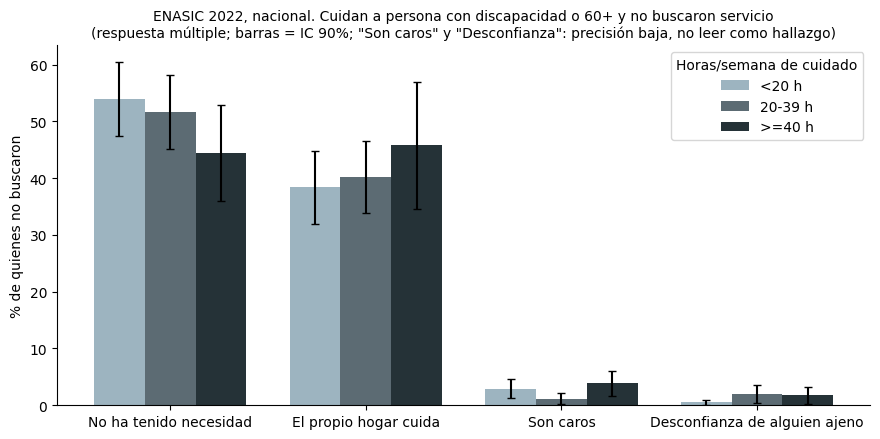

In [30]:
# Figura: razones principales por horas de cuidado, con IC al 90%
sel = ['No ha tenido necesidad', 'El propio hogar cuida', 'Son caros', 'Desconfianza de alguien ajeno']
fig, ax = plt.subplots(figsize=(9, 4.5))
segs = ['<20 h', '20-39 h', '>=40 h']; colores = ['#9DB4C0', '#5C6B73', '#253237']
x = np.arange(len(sel)); ancho = 0.26
for i, s in enumerate(segs):
    t = r_horas[r_horas.segmento == s].set_index('razon').loc[sel]
    err = np.vstack([t.pct - t.li90, t.ls90 - t.pct])
    ax.bar(x + (i - 1) * ancho, t.pct, ancho, yerr=err, capsize=3, label=s, color=colores[i])
ax.set_xticks(x, sel); ax.set_ylabel('% de quienes no buscaron'); ax.legend(title='Horas/semana de cuidado')
ax.set_title('ENASIC 2022, nacional. Cuidan a persona con discapacidad o 60+ y no buscaron servicio\n(respuesta múltiple; barras = IC 90%; "Son caros" y "Desconfianza": precisión baja, no leer como hallazgo)', fontsize=10)
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout()
plt.savefig(FIG / 'f9_razones_no_buscar_por_horas.png', dpi=150); plt.show()

## 11. Lectura

Todo es **nacional** y se lee de `resultados/07_enasic_necesidad_vs_norma_estimaciones.csv` y `resultados/07_enasic_diferencias.csv`.

**0. Validación.** El universo reproduce el notebook 03: buscó servicio 2.5%, "no tuvo necesidad" 49.4%, "el propio hogar cuida" 41.9%.

**1. "No tuvo necesidad" casi no cambia con la intensidad del cuidado. Resultado según el criterio 1: se sostiene H-A, se rechaza H-B.**
- "No tuvo necesidad":
  - menos de 20 h a la semana: 53.9%;
  - 40 h o más: 44.4%;
  - la diferencia, 9.6 pp, tiene un IC al 90% de −0.1 a 19.2: no excluye el cero.
- En el grupo más exigente (ayuda para bañar, vestir, dar de comer o cambiar pañales **y** 40 h o más), 46.8% responde que no tuvo necesidad (precisión alta; 215 casos en muestra).
- Por dependencia la proporción tampoco se mueve: 47.8% con ayuda en ABVD contra 52.7% sin ella.
- Quien cuida el equivalente a un empleo de tiempo completo responde "no necesité" casi en la misma proporción que quien cuida pocas horas. La respuesta no refleja la carga.

**2. Detrás de "no tuve necesidad" hay costo medible. Se cumple el criterio 2.**
- De quienes dicen "no tuve necesidad" y cuidan 40 h o más, 70.5% declara algún daño a su salud o su trabajo. En el grupo de ABVD y 40 h o más, 79.6%.
- Con menos de 20 h, el 42.6%. La diferencia, 27.9 pp (IC 90%: 17.1 a 38.7), sí excluye el cero.
- "Salud física deteriorada": 31.4% con 40 h o más contra 9.3% con menos de 20 h (precisión moderada).
- Entre quienes dicen "el propio hogar cuida", 61.1% declara algún daño.

**3. Tamaño del grupo (expandido, nacional).**
- 40.7% del universo cuida 40 h o más.
- 22.0%, unas 1.37 millones de personas, cuida 40 h o más **y** ayuda en actividades básicas.
- 12.5%, unas 0.78 millones, cuida 40 h o más, dice "no tuve necesidad" **y** declara algún daño.

Ese último grupo es la **población del problema**: carga alta, costo declarado, necesidad no reconocida. No es "el 97.5% que no busca".

**4. El precio no aparece en ningún segmento con precisión suficiente.** "Son caros" va de 1.5% a 5.4% por grupo de ingreso, y todas las celdas tienen precisión baja. No se puede afirmar que el precio frene la búsqueda en algún quintil. Eso no descarta el precio como barrera para **contratar cuidado en casa**, que P6.45 no mide.

**5. La norma se mide de forma directa, y es fuerte.**
- 82.3% dice que el apoyo a las personas mayores lo debe dar principalmente la familia (P7.7).
- 54.3% no está de acuerdo en llevarlas a residencias o casas de día. Pero **36.3% sí acepta "solo unas horas del día"** (P7.8). Esa es la ventana para un servicio de relevo por horas.
- 82.0% dice que cuida por "iniciativa propia" (P6.38). La norma está interiorizada: no se vive como obligación impuesta.

**6. La desconfianza existe, pero hacia las instituciones y en segundo lugar.**
- De quienes no aceptarían que los cuidaran en una residencia (54.2%):
  - 48.0% dice que es responsabilidad de la familia;
  - 25.3% dice que "tratan mal a las personas" (precisión alta).
- En P6.45, la desconfianza de que alguien ajeno cuide es 1.5% (precisión baja) en el universo y 1.4% (alta) en todas las cuidadoras.
- La comparación "doméstico 24.3% contra cuidado 2.6% en el quintil alto" no sostiene la hipótesis de confianza. El 2.6% viene de 7 casos, con CV de 46% (precisión baja), y el propio doméstico tiene precisión moderada.

**7. Conciliación de cifras.**
- **2.5%** es "buscó" entre quienes cuidan a una persona con discapacidad o 60+. Tiene **precisión baja** (CV 30.5%, 24 casos) y **no debe citarse como hallazgo**.
- **3.0%** es el mismo dato para todas las personas cuidadoras (precisión alta). Es el que se puede citar.
- **1.6%** ("desconoce que existen", universo discapacidad o 60+) también tiene precisión baja. Se citó en el registro del 22 y 23 de septiembre y hay que corregirlo.
- **0.9%** (todas las cuidadoras, precisión moderada) es la cifra citable.

**Qué implica (probable, nacional):**
- El problema no es que las familias no encuentren servicios. Es que **una parte grande de quienes cuidan con alta intensidad asume la carga como propia, no la nombra como necesidad y la paga con su salud y su trabajo**.
- Eso respalda un programa dirigido a la **persona cuidadora** más que un buscador o un subsidio de precio.
- El formato con más respaldo es el **relevo por horas**, compatible con el 36.3% que acepta "solo unas horas".
- La confianza entra como condición del diseño (la mala reputación de las residencias), no como la barrera central.

**Límites.**
1. "No tuve necesidad" responde a una pregunta sobre *lugares* (guardería, casa del abuelo, asilo). Una lectura alternativa, que estos datos **no pueden descartar**, es que sí necesitan apoyo pero no un *lugar*. Eso es compatible con el 58% que prefiere el cuidado en casa (notebook 03).
2. Los daños son autodeclarados y no prueban que un servicio los evitaría. Tampoco se puede descartar la **deseabilidad social**: decir "no tuve necesidad" puede ser la respuesta socialmente esperada, no una evaluación de la propia carga. El resultado es **compatible** con H-A, no la demuestra.
3. **Sensibilidad (5.1):** con cuartiles ponderados (Q1 ≤ 14 h, Q4 > 54 h) la conclusión no cambia. "No tuvo necesidad" 52.3% contra 43.4%, diferencia no significativa; algún daño entre "sin necesidad" 75.8% contra 44.2%, diferencia significativa.
4. Las horas de `P6_26` pueden incluir cuidado a menores.
5. Nada de esto es para la CDMX ni tiene tendencia.
6. **Pendiente de doble revisión.**

<a id="s12"></a>

---

*Sección 12 · antes `12_enasic_segmentacion_observatorio.ipynb`*

# 12 · ENASIC 2022: indicadores del Observatorio por segmento de la persona cuidadora.

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-10-06. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Para qué existe
  Alimentar los filtros de segmentación del Observatorio (pestañas Necesidad y Barreras). Cada cifra que la página
  muestra al filtrar sale de este archivo, con su coeficiente de variación, intervalo al 90% y muestra.

Universo
  Personas cuidadoras de una persona con discapacidad o de 60 años y más (TPOB_CUI, FILTRO6_1 o FILTRO6_6), igual que los
  notebooks 03, 07 y 11. Factor FAC_CUI. Varianza por linealización de Taylor con EST_DIS y UPM_DIS.

Segmentos (una dimensión a la vez; no se cruzan dos dimensiones porque las muestras se vuelven demasiado chicas)
  Sexo · Edad (15-39, 40-59, 60+) · Ingreso del hogar (Q1-Q2, Q3, Q4-Q5; cortes del script 04) ·
  A quién cuida (discapacidad / solo 60+ sin discapacidad) · Intensidad (<20, 20-39, >=40 h).

Para cada segmento y cada indicador se compara contra el resto del universo (segmento menos resto, en puntos
porcentuales, con IC al 90%). Eso permite que la página diga si la diferencia es significativa.

Limitaciones (leer antes de citar)
  - NACIONAL. No permite afirmaciones para la CDMX ni por alcaldía.
  - Las celdas con CV >= 30% tienen precisión baja y no son hallazgo; la página las muestra rayadas.
  - P6.45 pregunta por lugares (guardería, casa de día, asilo), no por cuidado en casa.
  - Los daños son autodeclarados.

Datos: microdatos ENASIC 2022 en datos/enasic/ (no se suben al repositorio).
Salidas: resultados/12_segmentacion_estimaciones.csv
```

*Convertido de `12_enasic_segmentacion_observatorio.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [31]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [32]:
from pathlib import Path
import numpy as np, pandas as pd

BASE = Path('datos/enasic'); OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
Z90 = 1.6449


def tabla(nombre, archivo=None):
    archivo = archivo or f'conjunto_de_datos_{nombre}_enasic_2022.csv'
    df = pd.read_csv(BASE / f'conjunto_de_datos_{nombre}_enasic_2022' / 'conjunto_de_datos' / archivo, dtype=str)
    df.columns = [c.upper() for c in df.columns]
    return df


def _var_lin(df, z):
    t = pd.DataFrame({'h': df.EST_DIS.values, 'u': df.UPM_DIS.values, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z
    n_h = g.transform('size'); zbar = g.transform('mean')
    return ((n_h / (n_h - 1)).where(n_h > 1, 0) * (t.z - zbar) ** 2).sum()


def estimar(df, y, x, peso='FAC_CUI'):
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float); x = np.asarray(x, float)
    X = (w * x).sum(); Y = (w * y).sum(); R = Y / X if X > 0 else np.nan
    se = np.sqrt(_var_lin(df, w * (y - R * x) / X)) if X > 0 else np.nan
    cv = se / R * 100 if R > 0 else np.nan
    prec = 'no estimable' if not np.isfinite(cv) else ('alta' if cv < 15 else ('moderada' if cv < 30 else 'baja'))
    return dict(pct=R * 100, cv=cv, li90=(R - Z90 * se) * 100, ls90=(R + Z90 * se) * 100,
                n_muestra_dominio=int(x.sum()), n_muestra_si=int((y * x).sum()), total_expandido=Y, precision=prec)


def diferencia(df, y, x1, x2, peso='FAC_CUI'):
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float)
    x1 = np.asarray(x1, float); x2 = np.asarray(x2, float)
    X1, X2 = (w * x1).sum(), (w * x2).sum()
    if X1 == 0 or X2 == 0:
        return dict(dif_pp=np.nan, dif_li90=np.nan, dif_ls90=np.nan, dif_significativa=False)
    R1, R2 = (w * y * x1).sum() / X1, (w * y * x2).sum() / X2
    z = w * (y * x1 - R1 * x1) / X1 - w * (y * x2 - R2 * x2) / X2
    se = np.sqrt(_var_lin(df, z)); d = R1 - R2
    return dict(dif_pp=d * 100, dif_li90=(d - Z90 * se) * 100, dif_ls90=(d + Z90 * se) * 100,
                dif_significativa=bool((d - Z90 * se) * (d + Z90 * se) > 0))


def es(df, col, val='1'):
    return (df[col] == val).astype(int).to_numpy()

In [33]:
# ---------------------------------------------------------------- datos y variables (mismas definiciones que 07 y 11)
cui = tabla('tpob_cui')
hog = tabla('thogar', 'conjunto_de_datos_thogar_ensasic_2022.csv')   # typo del INEGI en el nombre

def num(col): return pd.to_numeric(cui[col], errors='coerce')
cui['HORAS'] = (num('P6_7').fillna(0) + num('P6_26').fillna(0)).clip(upper=168)
cui.loc[num('P6_7').isna() & num('P6_26').isna(), 'HORAS'] = np.nan
cui['G_HORAS'] = pd.cut(cui.HORAS, [0, 19.999, 39.999, 1000], labels=['<20 h', '20-39 h', '>=40 h']).astype(str)

def cualquiera(pares):
    return np.column_stack([(cui[a] == '1') | (cui[b] == '1') for a, b in pares]).any(axis=1).astype(int)
cui['DANO_SALUD'] = cualquiera([('P6_11_1', 'P6_30_1'), ('P6_11_3', 'P6_30_3'), ('P6_11_6', 'P6_30_6')])
cui['DANO_TRABAJO'] = cualquiera([('P6_12_1', 'P6_31_1'), ('P6_12_2', 'P6_31_2'), ('P6_12_5', 'P6_31_5')])
cui['DANO_ALGUNO'] = ((cui.DANO_SALUD + cui.DANO_TRABAJO) > 0).astype(int)

MID = {'1': 1800, '2': 4850.5, '3': 7100.5, '4': 9000.5, '5': 11000.5, '6': 13300.5, '7': 16050.5,
       '8': 19750.5, '9': 25500.5, '10': 37100.5, '11': 55000}
hog['ING'] = pd.to_numeric(hog.P3A_4.where(hog.P3A_4 != '99999'), errors='coerce').fillna(hog.P3A_5.map(MID))
nec = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')) & hog.ING.notna()
W_h = pd.to_numeric(hog.FAC_HOG)
def wq(v, w, q):
    o = np.argsort(v.values); c = np.cumsum(w.values[o]) / w.sum(); return v.values[o][np.searchsorted(c, q)]
cortes = [wq(hog.ING[nec], W_h[nec], q) for q in (.2, .4, .6, .8)]
assert cortes == [3200, 5000, 8000, 15000], f'Los cortes de quintil no coinciden con el script 04: {cortes}'
hog['QUINTIL'] = np.where(hog.ING.isna(), np.nan, np.digitize(hog.ING, cortes, right=True) + 1)
cui = cui.merge(hog[['LLAVEHOG', 'QUINTIL']], on='LLAVEHOG', how='left', validate='many_to_one')

edad = num('EDAD')
cui['G_SEXO'] = cui.SEXO.map({'1': 'Hombre', '2': 'Mujer'})
cui['G_EDAD'] = pd.cut(edad, [0, 39, 59, 130], labels=['15-39', '40-59', '60+']).astype(str)
cui['G_ING'] = cui.QUINTIL.map({1: 'Q1-Q2', 2: 'Q1-Q2', 3: 'Q3', 4: 'Q4-Q5', 5: 'Q4-Q5'})
cui['G_TIPO'] = np.where(cui.FILTRO6_1 == '1', 'Cuida discapacidad', 'Solo 60+ sin discapacidad')

DOM = ((cui.FILTRO6_1 == '1') | (cui.FILTRO6_6 == '1')).astype(int).to_numpy()
NOBUSCO = DOM * es(cui, 'P6_42', '2')
SINNEC = NOBUSCO * es(cui, 'P6_45_09')

In [34]:
# ---------------------------------------------------------------- indicadores: (clave, etiqueta, grupo, y, dominio)
IND = [
    ('busco', 'Buscó un servicio de cuidado (P6.42)', 'uso', es(cui, 'P6_42'), DOM),
    ('horas40', 'Cuida 40 h o más a la semana', 'carga', (cui.G_HORAS == '>=40 h').astype(int).to_numpy(), DOM),
    ('dano', 'Declara algún daño por cuidar', 'carga', cui.DANO_ALGUNO.to_numpy(), DOM),
    ('dano_sinnec', 'Declara daño, entre quienes dicen "no tuve necesidad"', 'carga', cui.DANO_ALGUNO.to_numpy(), SINNEC),
]
RAZ = [('P6_45_09', 'raz_necesidad', 'No tuvo necesidad'), ('P6_45_01', 'raz_hogar', 'El propio hogar cuida'),
       ('P6_45_02', 'raz_familia', 'Apoyan otros familiares'), ('P6_45_07', 'raz_lejania', 'Lejanía'),
       ('P6_45_03', 'raz_caros', 'Son caros'), ('P6_45_05', 'raz_desconoce', 'No saben que existen'),
       ('P6_45_06', 'raz_desconfianza', 'Desconfianza de alguien ajeno'), ('P6_45_08', 'raz_maltrato', 'Maltrato del personal')]
IND += [(k, et, 'razones', es(cui, col), NOBUSCO) for col, k, et in RAZ]
IND += [('pref_casa', 'En su casa', 'preferencia', es(cui, 'P6_46', '1'), DOM),
        ('pref_no', 'No contrataría a nadie', 'preferencia', es(cui, 'P6_46', '5'), DOM),
        ('pref_publica', 'Institución pública', 'preferencia', es(cui, 'P6_46', '2'), DOM),
        ('norma_familia', 'La familia debe dar el apoyo (P7.7)', 'norma', es(cui, 'P7_7', '4'), DOM),
        ('unas_horas', 'Acepta institución "solo unas horas" (P7.8)', 'norma', es(cui, 'P7_8', '1'), DOM),
        ('no_residencia', 'No está de acuerdo con llevarlas (P7.8)', 'norma', es(cui, 'P7_8', '4'), DOM)]

SEG = [('Total', 'Total', None)]
SEG += [('Sexo', g, 'G_SEXO') for g in ['Mujer', 'Hombre']]
SEG += [('Edad', g, 'G_EDAD') for g in ['15-39', '40-59', '60+']]
SEG += [('Ingreso', g, 'G_ING') for g in ['Q1-Q2', 'Q3', 'Q4-Q5']]
SEG += [('A quién cuida', g, 'G_TIPO') for g in ['Cuida discapacidad', 'Solo 60+ sin discapacidad']]
SEG += [('Intensidad', g, 'G_HORAS') for g in ['<20 h', '20-39 h', '>=40 h']]

filas = []
for dim, g, col in SEG:
    m = np.ones(len(cui), int) if col is None else (cui[col] == g).astype(int).to_numpy()
    for k, et, grupo, y, dom in IND:
        if dim == 'Intensidad' and k == 'horas40':
            continue   # trivial dentro del segmento de horas
        r = estimar(cui, y * dom * m, dom * m)
        f = dict(dimension=dim, segmento=g, clave=k, indicador=et, grupo=grupo) | r
        if col is not None:
            niveles = [s for d_, s, c_ in SEG if c_ == col]
            resto = (cui[col].isin(niveles) & (cui[col] != g)).astype(int).to_numpy()
            f |= diferencia(cui, y, dom * m, dom * resto)
        filas.append(f)
res = pd.DataFrame(filas)

In [35]:
# ---------------------------------------------------------------- validación contra 03 y 07
tot = res[res.dimension == 'Total'].set_index('clave').pct.round(1)
esperado = {'busco': 2.5, 'raz_necesidad': 49.4, 'raz_hogar': 41.9, 'horas40': 40.7, 'pref_casa': 58.1,
            'norma_familia': 82.3, 'unas_horas': 36.3, 'no_residencia': 54.3}
for k, v in esperado.items():
    assert abs(tot[k] - v) < 0.05, f'{k}: {tot[k]} no reproduce {v}'
g40 = res[(res.dimension == 'Intensidad') & (res.segmento == '>=40 h')].set_index('clave').pct.round(1)
assert abs(g40['dano_sinnec'] - 70.5) < 0.05 and abs(g40['raz_necesidad'] - 44.4) < 0.05
print('Validación: reproduce las cifras de los notebooks 03 y 07.')

cols = ['pct', 'cv', 'li90', 'ls90', 'dif_pp', 'dif_li90', 'dif_ls90']
res[cols] = res[cols].round(2)
res['total_expandido'] = res.total_expandido.round(0)
res.to_csv(OUT / '12_segmentacion_estimaciones.csv', index=False, encoding='utf-8-sig')
print(len(res), 'estimaciones;', (res.precision == 'alta').sum(), 'alta,', (res.precision == 'moderada').sum(), 'moderada,',
      (res.precision == 'baja').sum(), 'baja;', int(res.dif_significativa.fillna(False).sum()), 'diferencias significativas contra el resto.')

Validación: reproduce las cifras de los notebooks 03 y 07.
249 estimaciones; 135 alta, 18 moderada, 95 baja; 67 diferencias significativas contra el resto.


## Gráficas
Cada punto es un segmento contra el total nacional (línea punteada). Relleno: diferencia significativa contra el resto de su dimensión. Hueco: precisión baja, no se compara.

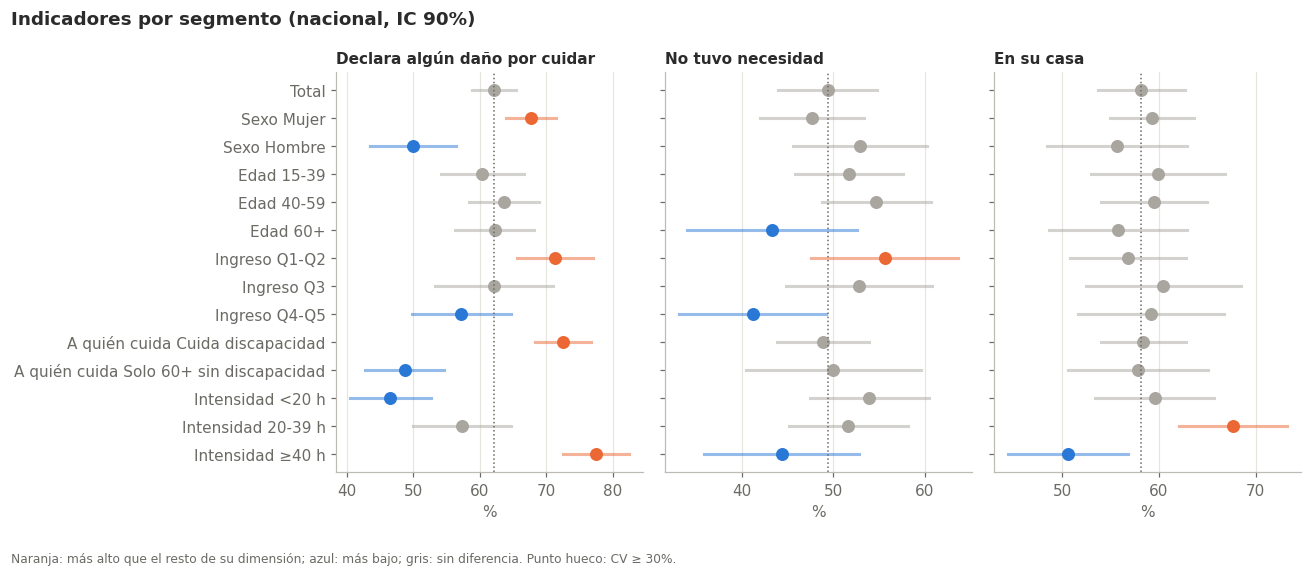

In [36]:
def forest(clave, ax):
    d = res[res.clave == clave].reset_index(drop=True)
    tot = d.loc[d.dimension == 'Total', 'pct'].iloc[0]
    y = np.arange(len(d))[::-1]
    for yi, (_, r) in zip(y, d.iterrows()):
        colr = (NARANJA if r.dif_pp > 0 else AZUL) if r.get('dif_significativa') is True else GRIS
        ax.plot([r.li90, r.ls90], [yi, yi], color=colr, lw=2, alpha=.5)
        ax.plot(r.pct, yi, 'o', ms=7, color=colr, mfc='white' if debil(r.precision) else colr, mew=1.5)
    ax.axvline(tot, color=TENUE, ls=':', lw=1)
    ax.set_yticks(y, (d.dimension.where(d.dimension != 'Total', '') + ' ' + d.segmento.str.replace('>=', '≥')).str.strip())
    ax.set_title(d.indicador.iloc[0], fontsize=10); ax.set_xlabel('%'); ax.grid(axis='y', visible=False)

fig, axs = plt.subplots(1, 3, figsize=(12, 5.2), sharey=False)
for ax, k in zip(axs, ['dano', 'raz_necesidad', 'pref_casa']):
    forest(k, ax)
for ax in axs[1:]:
    ax.set_yticklabels([])
fig.suptitle('Indicadores por segmento (nacional, IC 90%)', x=.01, ha='left', fontweight='bold')
nota(fig, 'Naranja: más alto que el resto de su dimensión; azul: más bajo; gris: sin diferencia. Punto hueco: CV ≥ 30%.')
plt.show()

### ¿Cuántas estimaciones sirven?

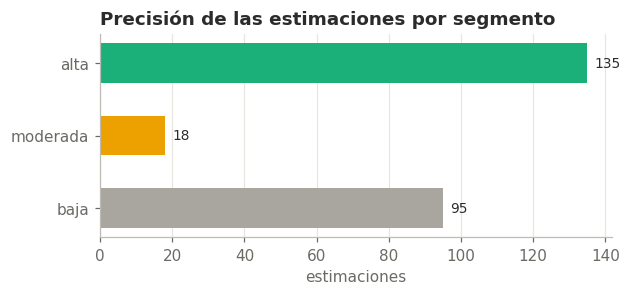

In [37]:
fig, ax = plt.subplots(figsize=(6, 2.4))
cuenta = res.precision.value_counts().reindex(['alta', 'moderada', 'baja']).fillna(0)
b = ax.barh(cuenta.index, cuenta.values, color=[AQUA, AMARILLO, GRIS], height=.55)
etiquetas(ax, b, cuenta.values, horizontal=True, fmt='{:.0f}', dx=2)
ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_xlabel('estimaciones'); ax.set_title('Precisión de las estimaciones por segmento')
plt.show()

<a id="s16"></a>

---

*Sección 16 · antes `16_enasic_perfil_grupo_horas.ipynb`*

# 16 · ENASIC 2022: perfil del grupo del problema y distribución de horas de cuidado.

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-10-06. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Para qué existe
  El problema prototípico pide "segmentación de perfiles agregados". El script 12 dice cómo cambia cada indicador
  dentro de un segmento; este script responde la pregunta inversa: ¿quiénes forman el grupo del problema?
  También reemplaza los tres cortes de horas (<20, 20-39, >=40) por la distribución completa.

Definiciones (las mismas que los notebooks 03, 07 y 11 y el script 12; el bloque de preparación se copió del 12)
  Universo: personas cuidadoras de una persona con discapacidad o de 60+ (TPOB_CUI, FILTRO6_1 o FILTRO6_6). FAC_CUI.
  Grupo del problema: universo y 40 h o más y no buscó servicio (P6.42 = 2) y "no tuve necesidad" (P6.45.09)
  y declara algún daño a su salud o su trabajo.
  Varianza por linealización de Taylor con EST_DIS y UPM_DIS; IC al 90%.

Qué permite afirmar y qué no
  - Composición nacional del grupo (qué % son mujeres, etc.). NO es una tasa de riesgo por segmento: eso es el script 12.
  - El grupo es un subconjunto del universo, así que la diferencia se prueba contra el RESTO del universo (dominios
    disjuntos), no contra el universo completo.
  - NACIONAL. No aplica a la CDMX ni a una alcaldía. Las horas son autodeclaradas (P6.7 + P6.26, tope 168).
  - El cuestionario topa cada bloque en "98 o más" (catálogo p6_7 y p6_26): los rangos altos están censurados.
    El archivo reporta qué proporción declaró el tope.

Salidas: resultados/16_perfil_grupo_problema.csv · resultados/16_distribucion_horas.csv
```

*Convertido de `16_enasic_perfil_grupo_horas.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [38]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [39]:
from pathlib import Path
import numpy as np, pandas as pd

BASE = Path('datos/enasic'); OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
Z90 = 1.6449


def tabla(nombre, archivo=None):
    archivo = archivo or f'conjunto_de_datos_{nombre}_enasic_2022.csv'
    df = pd.read_csv(BASE / f'conjunto_de_datos_{nombre}_enasic_2022' / 'conjunto_de_datos' / archivo, dtype=str)
    df.columns = [c.upper() for c in df.columns]
    return df


def _var_lin(df, z):
    t = pd.DataFrame({'h': df.EST_DIS.values, 'u': df.UPM_DIS.values, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z
    n_h = g.transform('size'); zbar = g.transform('mean')
    return ((n_h / (n_h - 1)).where(n_h > 1, 0) * (t.z - zbar) ** 2).sum()


def estimar(df, y, x, peso='FAC_CUI'):
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float); x = np.asarray(x, float)
    X = (w * x).sum(); Y = (w * y).sum(); R = Y / X if X > 0 else np.nan
    se = np.sqrt(_var_lin(df, w * (y - R * x) / X)) if X > 0 else np.nan
    cv = se / R * 100 if R > 0 else np.nan
    prec = 'no estimable' if not np.isfinite(cv) else ('alta' if cv < 15 else ('moderada' if cv < 30 else 'baja'))
    return dict(pct=R * 100, cv=cv, li90=(R - Z90 * se) * 100, ls90=(R + Z90 * se) * 100,
                n_muestra_dominio=int(x.sum()), n_muestra_si=int((y * x).sum()), total_expandido=Y, precision=prec)


def diferencia(df, y, x1, x2, peso='FAC_CUI'):
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float)
    x1 = np.asarray(x1, float); x2 = np.asarray(x2, float)
    X1, X2 = (w * x1).sum(), (w * x2).sum()
    if X1 == 0 or X2 == 0:
        return dict(dif_pp=np.nan, dif_li90=np.nan, dif_ls90=np.nan, dif_significativa=False)
    R1, R2 = (w * y * x1).sum() / X1, (w * y * x2).sum() / X2
    z = w * (y * x1 - R1 * x1) / X1 - w * (y * x2 - R2 * x2) / X2
    se = np.sqrt(_var_lin(df, z)); d = R1 - R2
    return dict(dif_pp=d * 100, dif_li90=(d - Z90 * se) * 100, dif_ls90=(d + Z90 * se) * 100,
                dif_significativa=bool((d - Z90 * se) * (d + Z90 * se) > 0))


def es(df, col, val='1'):
    return (df[col] == val).astype(int).to_numpy()

In [40]:
# ---------------------------------------------------------------- datos y variables (mismas definiciones que 07 y 11)
cui = tabla('tpob_cui')
hog = tabla('thogar', 'conjunto_de_datos_thogar_ensasic_2022.csv')   # typo del INEGI en el nombre

def num(col): return pd.to_numeric(cui[col], errors='coerce')
cui['HORAS'] = (num('P6_7').fillna(0) + num('P6_26').fillna(0)).clip(upper=168)
cui.loc[num('P6_7').isna() & num('P6_26').isna(), 'HORAS'] = np.nan
cui['G_HORAS'] = pd.cut(cui.HORAS, [0, 19.999, 39.999, 1000], labels=['<20 h', '20-39 h', '>=40 h']).astype(str)

def cualquiera(pares):
    return np.column_stack([(cui[a] == '1') | (cui[b] == '1') for a, b in pares]).any(axis=1).astype(int)
cui['DANO_SALUD'] = cualquiera([('P6_11_1', 'P6_30_1'), ('P6_11_3', 'P6_30_3'), ('P6_11_6', 'P6_30_6')])
cui['DANO_TRABAJO'] = cualquiera([('P6_12_1', 'P6_31_1'), ('P6_12_2', 'P6_31_2'), ('P6_12_5', 'P6_31_5')])
cui['DANO_ALGUNO'] = ((cui.DANO_SALUD + cui.DANO_TRABAJO) > 0).astype(int)

MID = {'1': 1800, '2': 4850.5, '3': 7100.5, '4': 9000.5, '5': 11000.5, '6': 13300.5, '7': 16050.5,
       '8': 19750.5, '9': 25500.5, '10': 37100.5, '11': 55000}
hog['ING'] = pd.to_numeric(hog.P3A_4.where(hog.P3A_4 != '99999'), errors='coerce').fillna(hog.P3A_5.map(MID))
nec = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')) & hog.ING.notna()
W_h = pd.to_numeric(hog.FAC_HOG)
def wq(v, w, q):
    o = np.argsort(v.values); c = np.cumsum(w.values[o]) / w.sum(); return v.values[o][np.searchsorted(c, q)]
cortes = [wq(hog.ING[nec], W_h[nec], q) for q in (.2, .4, .6, .8)]
assert cortes == [3200, 5000, 8000, 15000], f'Los cortes de quintil no coinciden con el script 04: {cortes}'
hog['QUINTIL'] = np.where(hog.ING.isna(), np.nan, np.digitize(hog.ING, cortes, right=True) + 1)
cui = cui.merge(hog[['LLAVEHOG', 'QUINTIL']], on='LLAVEHOG', how='left', validate='many_to_one')

edad = num('EDAD')
cui['G_SEXO'] = cui.SEXO.map({'1': 'Hombre', '2': 'Mujer'})
cui['G_EDAD'] = pd.cut(edad, [0, 39, 59, 130], labels=['15-39', '40-59', '60+']).astype(str)
cui['G_ING'] = cui.QUINTIL.map({1: 'Q1-Q2', 2: 'Q1-Q2', 3: 'Q3', 4: 'Q4-Q5', 5: 'Q4-Q5'})
cui['G_TIPO'] = np.where(cui.FILTRO6_1 == '1', 'Cuida discapacidad', 'Solo 60+ sin discapacidad')

DOM = ((cui.FILTRO6_1 == '1') | (cui.FILTRO6_6 == '1')).astype(int).to_numpy()
NOBUSCO = DOM * es(cui, 'P6_42', '2')
SINNEC = NOBUSCO * es(cui, 'P6_45_09')


DOM = ((cui.FILTRO6_1 == '1') | (cui.FILTRO6_6 == '1')).astype(int).to_numpy()
NOBUSCO = DOM * es(cui, 'P6_42', '2')
SINNEC = NOBUSCO * es(cui, 'P6_45_09')
H40 = (cui.G_HORAS == '>=40 h').astype(int).to_numpy()
GRUPO = SINNEC * H40 * cui.DANO_ALGUNO.to_numpy()

In [41]:
# ---------------------------------------------------------------- validación contra el embudo (notebook 07)
g = estimar(cui, GRUPO, DOM)
assert abs(g['total_expandido'] - 775546) < 1, f"El grupo no reproduce el embudo: {g['total_expandido']:.0f}"
assert abs(estimar(cui, H40 * DOM, DOM)['pct'] - 40.7) < 0.05
print(f"Validación: grupo del problema = {g['total_expandido']:,.0f} personas ({g['pct']:.1f}% del universo), igual que el notebook 07.")

Validación: grupo del problema = 775,546 personas (12.5% del universo), igual que el notebook 07.


In [42]:
# ---------------------------------------------------------------- 1. perfil: composición del grupo frente al universo
cui['G_ING2'] = cui.G_ING.fillna('Sin dato').replace('nan', 'Sin dato')
DIMS = [('Sexo', 'G_SEXO', ['Mujer', 'Hombre']),
        ('Edad', 'G_EDAD', ['15-39', '40-59', '60+']),
        ('Ingreso', 'G_ING2', ['Q1-Q2', 'Q3', 'Q4-Q5', 'Sin dato']),
        ('A quién cuida', 'G_TIPO', ['Cuida discapacidad', 'Solo 60+ sin discapacidad'])]
filas = []
for dim, col, niveles in DIMS:
    for nv in niveles:
        y = (cui[col] == nv).astype(int).to_numpy()
        for pob, x in [('Grupo del problema', GRUPO), ('Universo', DOM)]:
            f = dict(dimension=dim, segmento=nv, poblacion=pob) | estimar(cui, y * x, x)
            if pob == 'Grupo del problema':
                f |= diferencia(cui, y, GRUPO, DOM * (1 - GRUPO))   # grupo contra el resto del universo
            filas.append(f)
    # las categorías de cada dimensión deben sumar 100% (nadie queda fuera)
    for pob in ('Grupo del problema', 'Universo'):
        s = sum(f['pct'] for f in filas if f['dimension'] == dim and f['poblacion'] == pob)
        assert abs(s - 100) < 0.01, f'{dim}/{pob} suma {s:.2f}%'
perfil = pd.DataFrame(filas)

In [43]:
# ---------------------------------------------------------------- 2. distribución de horas semanales (universo)
CORTES = [(1, 9), (10, 19), (20, 29), (30, 39), (40, 59), (60, 89), (90, 119), (120, 168)]   # 120+ junto: menos de 1.5%
hrs = cui.HORAS
VAL = DOM * hrs.notna().astype(int).to_numpy()
filas = []
for a, b in CORTES:
    y = (hrs.between(a, b)).astype(int).to_numpy()
    filas.append(dict(desde=a, hasta=b, etiqueta=(f'{a}-{b}' if a != b else f'{a}'), universo='Universo con horas válidas')
                 | estimar(cui, y * VAL, VAL))
horas = pd.DataFrame(filas)
sin_horas = estimar(cui, DOM * hrs.isna().astype(int).to_numpy(), DOM)
tope98 = estimar(cui, VAL * ((cui.P6_7 == '98') | (cui.P6_26 == '98')).astype(int).to_numpy(), VAL)
cero = estimar(cui, VAL * (hrs < 1).astype(int).to_numpy(), VAL)
assert abs(horas.pct.sum() + cero['pct'] - 100) < 0.01, 'Los rangos de horas no cubren el universo'
w = pd.to_numeric(cui.FAC_CUI)[VAL == 1]; v = hrs[VAL == 1]
o = np.argsort(v.values); c = np.cumsum(w.values[o]) / w.sum()
med = float(v.values[o][np.searchsorted(c, .5)])
horas = pd.concat([horas, pd.DataFrame([
    dict(desde=np.nan, hasta=np.nan, etiqueta='sin dato de horas', universo='Universo (incluye sin dato)') | sin_horas,
    dict(desde=98, hasta=np.nan, etiqueta='declara el tope "98 o más" en un bloque', universo='Universo con horas válidas') | tope98,
    dict(desde=np.nan, hasta=np.nan, etiqueta='mediana ponderada (horas)', universo='Universo con horas válidas',
         pct=med, precision='sin varianza', n_muestra_dominio=int(VAL.sum()))])], ignore_index=True)
print(f"Horas: mediana ponderada {med:.0f} h; {sin_horas['pct']:.1f}% sin dato; {tope98['pct']:.1f}% declara el tope de 98 h.")

for df, nombre in [(perfil, '16_perfil_grupo_problema.csv'), (horas, '16_distribucion_horas.csv')]:
    cols = [c for c in ['pct', 'cv', 'li90', 'ls90', 'dif_pp', 'dif_li90', 'dif_ls90'] if c in df]
    df[cols] = df[cols].astype(float).round(2)
    df['total_expandido'] = df.total_expandido.round(0)
    df.to_csv(OUT / nombre, index=False, encoding='utf-8-sig')
print(perfil[['dimension', 'segmento', 'poblacion', 'pct', 'cv', 'precision', 'n_muestra_dominio', 'dif_pp', 'dif_significativa']].to_string(index=False))
print(horas[['etiqueta', 'pct', 'cv', 'precision', 'n_muestra_dominio']].to_string(index=False))

Horas: mediana ponderada 30 h; 0.0% sin dato; 3.3% declara el tope de 98 h.
    dimension                  segmento          poblacion   pct    cv precision  n_muestra_dominio  dif_pp dif_significativa
         Sexo                     Mujer Grupo del problema 77.79  5.99      alta                132   10.29              True
         Sexo                     Mujer           Universo 68.78  2.42      alta               1043     NaN               NaN
         Sexo                    Hombre Grupo del problema 22.21 20.96  moderada                132  -10.29              True
         Sexo                    Hombre           Universo 31.22  5.32      alta               1043     NaN               NaN
         Edad                     15-39 Grupo del problema 34.12 13.68      alta                132    7.27             False
         Edad                     15-39           Universo 27.75  6.79      alta               1043     NaN               NaN
         Edad                     40-59 Gr

## Gráficas
### ¿Quiénes forman el grupo del problema?
Composición del grupo contra el universo. ★ = el grupo difiere del resto del universo.

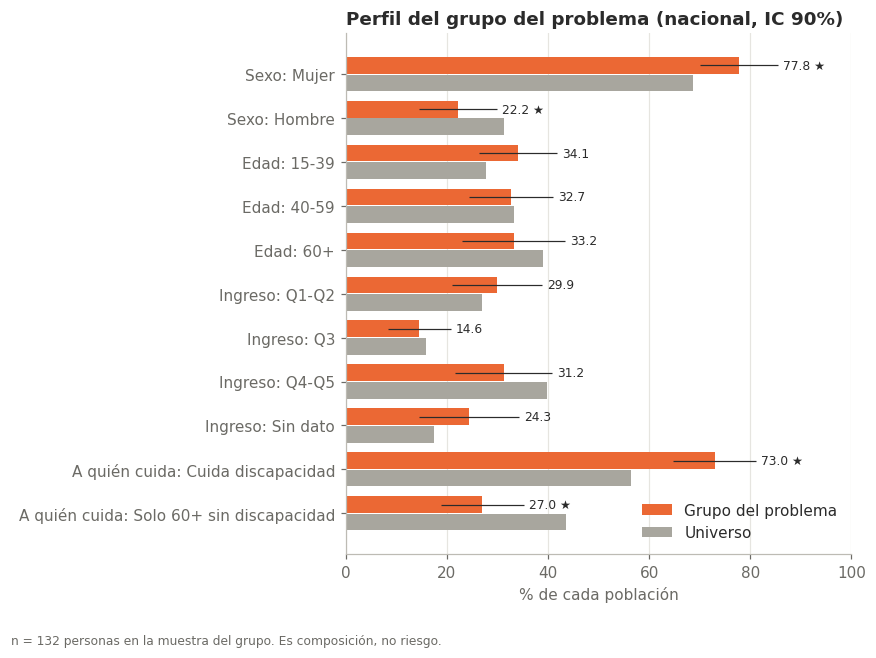

In [44]:
g = perfil[perfil.poblacion == 'Grupo del problema'].reset_index(drop=True)
u = perfil[perfil.poblacion == 'Universo'].set_index(['dimension', 'segmento'])
fig, ax = plt.subplots(figsize=(8, 6)); y = np.arange(len(g))[::-1]
b1 = ax.barh(y + .2, g.pct, .38, color=NARANJA, label='Grupo del problema', xerr=[g.pct - g.li90, g.ls90 - g.pct], error_kw=dict(ecolor=TINTA, lw=.8))
marcar_debiles(b1, g.precision, NARANJA)
uv = [u.loc[(r.dimension, r.segmento), 'pct'] for r in g.itertuples()]
b2 = ax.barh(y - .2, uv, .38, color=GRIS, label='Universo')
for yi, r in zip(y, g.itertuples()):
    ax.text(r.ls90 + 1, yi + .2, f'{r.pct:.1f}' + (' ★' if r.dif_significativa is True else ''), va='center', fontsize=8)
ax.set_yticks(y, g.dimension + ': ' + g.segmento); ax.set_xlim(0, 100); ax.grid(axis='y', visible=False)
ax.set_xlabel('% de cada población'); ax.legend(loc='lower right'); ax.set_title('Perfil del grupo del problema (nacional, IC 90%)')
nota(fig, f'n = {g.n_muestra_dominio.iloc[0]} personas en la muestra del grupo. Es composición, no riesgo.'); plt.show()

### ¿Cuántas horas a la semana cuidan?

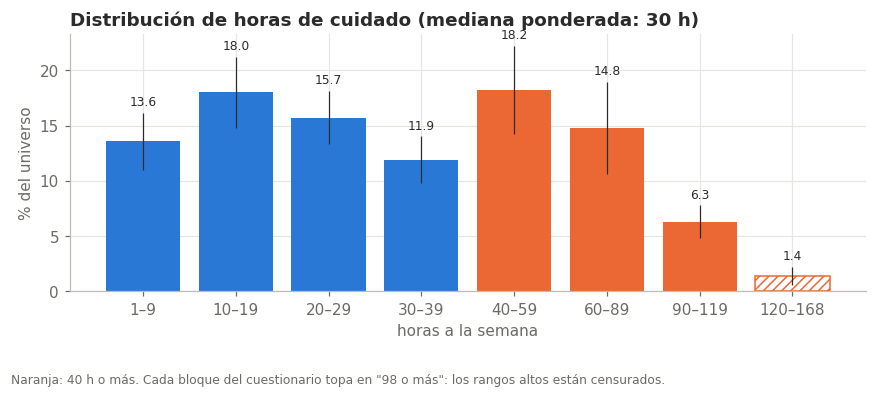

In [45]:
r = horas[horas.desde.notna() & horas.hasta.notna()].sort_values('desde').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = [NARANJA if d >= 40 else AZUL for d in r.desde]
b = ax.bar(r.etiqueta.str.replace('-', '–'), r.pct, color=cols, width=.8, yerr=[r.pct - r.li90.clip(lower=0), r.ls90 - r.pct], error_kw=dict(ecolor=TINTA, lw=.8))
marcar_debiles(b, r.precision, NARANJA)
for bb, pc, hi in zip(b, r.pct, r.ls90):
    ax.text(bb.get_x() + bb.get_width() / 2, hi + .4, f'{pc:.1f}', ha='center', va='bottom', fontsize=8)
med = horas.loc[horas.etiqueta == 'mediana ponderada (horas)', 'pct'].iloc[0]
ax.set_xlabel('horas a la semana'); ax.set_ylabel('% del universo')
ax.set_title(f'Distribución de horas de cuidado (mediana ponderada: {med:.0f} h)')
nota(fig, 'Naranja: 40 h o más. Cada bloque del cuestionario topa en "98 o más": los rangos altos están censurados.'); plt.show()

<a id="s11"></a>

---

*Sección 11 · antes `11_modelo_focalizacion_cuidadoras.ipynb`*

# 11 — Modelo de focalización: ¿qué personas cuidadoras declaran daño por cuidar?

**Para qué decisión existe este notebook.** El programa elegido el 5 oct 2026 (opción C) ofrece relevo por horas a
la persona cuidadora familiar de alta intensidad. Una institución que lo opere tiene que decidir **a quién ofrecerlo
primero** con la información que puede pedir al registrar a alguien. Este notebook compara dos formas de decidir:

- **Regla simple (línea base):** ofrecer relevo a quien cuida 40 h o más a la semana.
- **Modelo:** estimar la probabilidad de que la persona declare daño por cuidar a partir de varias respuestas de
  registro, y ofrecer relevo a quien tenga la probabilidad más alta.

La comparación es justa solo si los dos seleccionan **la misma cantidad de personas**. Se fija esa cantidad en la
proporción que selecciona la regla (quienes cuidan 40 h o más) y se pregunta cuál de los dos encuentra más personas
con daño. Si la regla iguala al modelo, el resultado es válido: la regla es más barata y más fácil de explicar.

**Variable objetivo.** `DANO_ALGUNO`, la misma definición del notebook 07: la persona declara por cuidar al menos uno
de estos daños: salud física deteriorada, cansancio, menos horas de sueño, imposibilidad de trabajar fuera, dejar de
trabajar o reducir la jornada. Sensibilidad con un objetivo más estricto: salud física deteriorada.

**Predictores (información de registro).** Solo variables que una institución podría preguntar al inscribir a una
persona y que **no son consecuencias del cuidado**. Se excluyen a propósito:
- todas las preguntas de daño (P6.10, P6.11, P6.12, P6.29, P6.30, P6.31), porque son el objetivo o casi el objetivo;
- la condición de actividad económica (CPEA) y el trabajo de la semana pasada (sección 5), porque "dejó de trabajar"
  forma parte del objetivo y estar sin empleo puede ser consecuencia del cuidado;
- las razones para no buscar servicios (P6.45) y la norma (P7), porque no son información de registro.

**Alcance.** Nacional, ENASIC 2022, personas cuidadoras de una persona con discapacidad o de 60 años y más
(mismo universo que los notebooks 03 y 07). No permite afirmaciones sobre la CDMX. Microdatos públicos del INEGI;
aquí solo se publican métricas agregadas.

**Qué NO demuestra.** Que el relevo reduzca el daño. El modelo solo ordena a quién ofrecerlo primero.

In [46]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
BASE = Path('datos/enasic'); OUT = Path('resultados'); OUT.mkdir(exist_ok=True); FIG = Path('figuras'); FIG.mkdir(exist_ok=True)
SEMILLA = 20261005

def tabla(nombre, archivo=None):
    archivo = archivo or f'conjunto_de_datos_{nombre}_enasic_2022.csv'
    df = pd.read_csv(BASE / f'conjunto_de_datos_{nombre}_enasic_2022' / 'conjunto_de_datos' / archivo, dtype=str)
    df.columns = [c.upper() for c in df.columns]
    return df

cui = tabla('tpob_cui')
hog = tabla('thogar', 'conjunto_de_datos_thogar_ensasic_2022.csv')   # typo del INEGI en el nombre
print('TPOB_CUI', cui.shape, '| THOGAR', hog.shape)

TPOB_CUI (5677, 432) | THOGAR (6508, 72)


## 1. Universo, objetivo y validación contra el notebook 07

Se reconstruyen exactamente las variables del notebook 07 (horas, ABVD, daños). Si el porcentaje de daño en el
universo y el peso del grupo de 40 h o más no coinciden con el 07, algo está mal y no se sigue.

In [47]:
Z90 = 1.6449
def _var_lin(df, z):
    t = pd.DataFrame({'h': df.EST_DIS.values, 'u': df.UPM_DIS.values, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z; n_h = g.transform('size'); zbar = g.transform('mean')
    return ((n_h / (n_h - 1)).where(n_h > 1, 0) * (t.z - zbar) ** 2).sum()

def razon(df, y, x, peso='FAC_CUI'):
    """Razón ponderada sum(w*y)/sum(w*x) con error estándar de diseño (linealización de Taylor)."""
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float); x = np.asarray(x, float)
    X = (w * x).sum(); R = (w * y).sum() / X
    se = np.sqrt(_var_lin(df, w * (y - R * x) / X))
    return R, se

def es(col, val='1'): return (cui[col] == val).astype(int).to_numpy()
def num(col): return pd.to_numeric(cui[col], errors='coerce')

DOM = ((cui.FILTRO6_1 == '1') | (cui.FILTRO6_6 == '1')).to_numpy()
cui['HORAS'] = (num('P6_7').fillna(0) + num('P6_26').fillna(0)).clip(upper=168)
cui.loc[num('P6_7').isna() & num('P6_26').isna(), 'HORAS'] = np.nan

def cualquiera(pares):
    return np.column_stack([(cui[a] == '1') | (cui[b] == '1') for a, b in pares]).any(axis=1).astype(int)
cui['DANO_SALUD_FISICA'] = cualquiera([('P6_11_1', 'P6_30_1')])
cui['DANO_SALUD'] = cualquiera([('P6_11_1', 'P6_30_1'), ('P6_11_3', 'P6_30_3'), ('P6_11_6', 'P6_30_6')])
cui['DANO_TRABAJO'] = cualquiera([('P6_12_1', 'P6_31_1'), ('P6_12_2', 'P6_31_2'), ('P6_12_5', 'P6_31_5')])
cui['DANO_ALGUNO'] = ((cui.DANO_SALUD + cui.DANO_TRABAJO) > 0).astype(int)

d0 = cui[DOM].copy()
r_dano, se_dano = razon(d0, d0.DANO_ALGUNO, np.ones(len(d0)))
r_40, _ = razon(d0, (d0.HORAS >= 40).astype(int), np.ones(len(d0)))
print(f'Universo, muestra: {len(d0)} | sin horas: {d0.HORAS.isna().sum()}')
print(f'Algún daño (ponderado): {r_dano*100:.1f}%  (IC90 {100*(r_dano-Z90*se_dano):.1f}-{100*(r_dano+Z90*se_dano):.1f})')
print(f'Cuidan 40 h o más (ponderado): {r_40*100:.1f}%  (notebook 07: 40.7%)')
assert abs(r_40 * 100 - 40.7) < 0.1, 'No reproduce el 40.7% del notebook 07'

Universo, muestra: 1043 | sin horas: 0
Algún daño (ponderado): 62.2%  (IC90 58.8-65.6)
Cuidan 40 h o más (ponderado): 40.7%  (notebook 07: 40.7%)


## 2. Predictores de registro

| Predictor | De dónde sale | Por qué es información de registro |
|---|---|---|
| Horas semanales de cuidado | P6.7 + P6.26 (tope 168) | Se pregunta al inscribir |
| Número de actividades básicas en que ayuda (comer, vestir, pañales, bañar, acostar) | P6.2.01–04, 08 | Describe la dependencia de quien recibe |
| Número de tareas clínicas (medicamentos, curaciones, terapia, tratamientos) | P6.2.10–13 | Describe la complejidad del cuidado |
| Cuida a una persona con discapacidad (vs. solo 60+ sin discapacidad) | FILTRO6.1 | Tipo de cuidado |
| Cuida además a menores de 18 | FILTRO6.2–6.5 | Carga adicional |
| Años cuidando (0 en el bloque 60+, donde no se pregunta) | P6.6.1 | Se pregunta al inscribir |
| Recibió capacitación | P6.3 / P6.23 | Se pregunta al inscribir |
| Recibe apoyo económico de la familia | P6.8 / P6.27 | Se pregunta al inscribir |
| Requiere que otra persona le apoye para cuidar | P6.9.4 / P6.28.4 | Necesidad de apoyo, no daño |
| Le falta fuerza física para ayudar | P6.9.1 / P6.28.1 | Dificultad de la tarea, no daño |
| Sexo, edad, escolaridad | SEXO, EDAD, NIVEL | Datos de registro |
# | Quintil de ingreso del hogar | THOGAR, igual que el script 04 | Dato socioeconómico de registro |

**Advertencia.** El bloque "60+ sin discapacidad" no tiene preguntas de actividades básicas ni de tareas clínicas:
esas personas quedan con 0. El indicador de discapacidad le permite al modelo distinguir ese 0 de un 0 real.
En una institución real, varios de estos datos son personales y algunos sensibles; qué se puede pedir lo decide el
dictamen de Leyes, no este notebook (ver sección 8).

In [48]:
ABVD = ['P6_2_01', 'P6_2_02', 'P6_2_03', 'P6_2_04', 'P6_2_08']
CLIN = ['P6_2_10', 'P6_2_11', 'P6_2_12', 'P6_2_13']
cui['N_ABVD'] = (cui[ABVD] == '1').sum(axis=1)
cui['N_CLINICAS'] = (cui[CLIN] == '1').sum(axis=1)
cui['CUIDA_DISC'] = es('FILTRO6_1')
cui['CUIDA_MENORES'] = ((cui[['FILTRO6_2', 'FILTRO6_3']] == '1').any(axis=1)).astype(int)
anios = num('P6_6_1'); cui['ANIOS_CUIDANDO'] = anios.where(anios != 99)
# P6.6 solo se pregunta en el bloque de discapacidad: en el bloque 60+ se fija en 0 y CUIDA_DISC distingue ese 0.
cui.loc[cui.FILTRO6_1 != '1', 'ANIOS_CUIDANDO'] = 0
cui['CAPACITACION'] = ((cui.P6_3 == '1') | (cui.P6_23 == '1')).astype(int)
cui['APOYO_FAMILIA'] = ((cui.P6_8 == '1') | (cui.P6_27 == '1')).astype(int)
cui['REQUIERE_APOYO'] = ((cui.P6_9_4 == '1') | (cui.P6_28_4 == '1')).astype(int)
cui['FALTA_FUERZA'] = ((cui.P6_9_1 == '1') | (cui.P6_28_1 == '1')).astype(int)
cui['MUJER'] = es('SEXO', '2')
cui['EDAD_N'] = num('EDAD')
niv = num('NIVEL'); cui['ESCOLARIDAD'] = niv.where(niv != 9)

# Ingreso y quintil: misma construcción que 04 y 07.
MID = {'1': 1800, '2': 4850.5, '3': 7100.5, '4': 9000.5, '5': 11000.5, '6': 13300.5, '7': 16050.5,
       '8': 19750.5, '9': 25500.5, '10': 37100.5, '11': 55000}
hog['ING'] = pd.to_numeric(hog.P3A_4.where(hog.P3A_4 != '99999'), errors='coerce').fillna(hog.P3A_5.map(MID))
nec = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')) & hog.ING.notna()
W_h = pd.to_numeric(hog.FAC_HOG)
def wq(v, w, q):
    o = np.argsort(v.values); c = np.cumsum(w.values[o]) / w.sum(); return v.values[o][np.searchsorted(c, q)]
cortes = [wq(hog.ING[nec], W_h[nec], q) for q in (.2, .4, .6, .8)]
hog['QUINTIL'] = np.where(hog.ING.isna(), np.nan, np.digitize(hog.ING, cortes, right=True) + 1)
cui = cui.merge(hog[['LLAVEHOG', 'QUINTIL']], on='LLAVEHOG', how='left', validate='many_to_one')
print('Cortes de quintil:', cortes, '(04 y 07: 3200, 5000, 8000, 15000)')

PRED = ['HORAS', 'N_ABVD', 'N_CLINICAS', 'CUIDA_DISC', 'CUIDA_MENORES', 'ANIOS_CUIDANDO', 'CAPACITACION',
        'APOYO_FAMILIA', 'REQUIERE_APOYO', 'FALTA_FUERZA', 'MUJER', 'EDAD_N', 'ESCOLARIDAD', 'QUINTIL']
d = cui[DOM].reset_index(drop=True).copy()
print('\nFaltantes por predictor (muestra del universo):')
print(d[PRED].isna().sum()[lambda s: s > 0].to_string())

Cortes de quintil: [np.float64(3200.0), np.float64(5000.0), np.float64(8000.0), np.float64(15000.0)] (04 y 07: 3200, 5000, 8000, 15000)

Faltantes por predictor (muestra del universo):
ANIOS_CUIDANDO      1
ESCOLARIDAD         1
QUINTIL           184


## 3. Validación cruzada que respeta el diseño muestral

- **Particiones por UPM.** Las personas de una misma unidad primaria de muestreo se parecen entre sí. Si unas caen en
  entrenamiento y otras en prueba, el desempeño se infla. Por eso las particiones agrupan por `UPM_DIS`.
- **5 particiones × 20 repeticiones** con semillas distintas; para cada persona se promedia su probabilidad fuera de
  muestra.
- **Pesos.** Los modelos se entrenan con `FAC_CUI` como peso de muestra, y todas las métricas son ponderadas, para
  que describan a la población y no a la muestra.
- **Faltantes.** La regresión logística imputa la mediana del conjunto de entrenamiento y agrega un indicador de
  faltante; el gradient boosting los maneja de forma nativa.

Modelos comparados:
1. **Regla ≥ 40 h** (línea base de negocio).
2. **Horas como puntaje continuo** (línea base estadística: misma información que la regla, sin el corte).
3. **Regresión logística** con todos los predictores (interpretable).
4. **Gradient boosting** (`HistGradientBoostingClassifier`, poco profundo para no sobreajustar con ~1,000 casos).

In [49]:
y = d.DANO_ALGUNO.to_numpy()
w = pd.to_numeric(d.FAC_CUI).to_numpy(float)
grupos = d.UPM_DIS.to_numpy()
X = d[PRED].astype(float)

def prep_logit(Xtr, Xte):
    med = Xtr.median()
    a = Xtr.fillna(med); b = Xte.fillna(med)
    for c in ['QUINTIL']:   # único predictor con faltantes relevantes (hogar sin dato de ingreso)
        a[c + '_NA'] = Xtr[c].isna().astype(int); b[c + '_NA'] = Xte[c].isna().astype(int)
    return a, b

def oof(modelo, objetivo, reps=20, k=5):
    acum = np.zeros(len(d)); cuenta = np.zeros(len(d))
    for r in range(reps):
        gkf = GroupKFold(n_splits=k, shuffle=True, random_state=SEMILLA + r)
        for tr, te in gkf.split(X, objetivo, grupos):
            Xtr, Xte = X.iloc[tr], X.iloc[te]
            if modelo == 'logit':
                Xtr, Xte = prep_logit(Xtr, Xte)
                m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
                m.fit(Xtr, objetivo[tr], logisticregression__sample_weight=w[tr])
            else:
                m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=30,
                                                   l2_regularization=1.0, random_state=SEMILLA + r)
                m.fit(Xtr, objetivo[tr], sample_weight=w[tr])
            acum[te] += m.predict_proba(Xte)[:, 1]; cuenta[te] += 1
    return acum / cuenta

horas = d.HORAS.fillna(d.HORAS.median()).to_numpy()
punt = {'Regla >= 40 h': (d.HORAS >= 40).astype(float).to_numpy(),
        'Horas (continuo)': horas,
        'Regresión logística': oof('logit', y),
        'Gradient boosting': oof('hgb', y)}
print('Listo:', list(punt))

Listo: ['Regla >= 40 h', 'Horas (continuo)', 'Regresión logística', 'Gradient boosting']


## 4. Resultados globales

- **AUC ponderado:** qué tan bien ordena cada puntaje a quien declara daño por encima de quien no (0.5 = azar).
  La regla solo tiene dos valores, así que su AUC es el de un único corte.
- **A la misma tasa de selección que la regla:** cada puntaje selecciona la misma proporción ponderada de personas
  que la regla (las que cuidan 40 h o más). Se reporta qué proporción de las seleccionadas declara daño
  (**precisión**) y qué proporción de todas las personas con daño queda seleccionada (**cobertura**).
- La diferencia de cobertura contra la regla se estima con error estándar de diseño (IC al 90%).

In [50]:
tasa = (w * punt['Regla >= 40 h']).sum() / w.sum()
def seleccionar(s, tasa):
    """Selecciona la proporción ponderada `tasa` con el puntaje más alto (desempates al azar con semilla fija)."""
    rng = np.random.default_rng(SEMILLA)
    o = np.lexsort((rng.random(len(s)), -s))
    acum = np.cumsum(w[o]) / w.sum()
    sel = np.zeros(len(s), int); sel[o[acum <= tasa + 1e-12]] = 1
    return sel

sel = {k: (v.astype(int) if k == 'Regla >= 40 h' else seleccionar(v, tasa)) for k, v in punt.items()}
filas = []
for k, s in punt.items():
    f = sel[k]
    prec, se_p = razon(d, y * f, f); cob, se_c = razon(d, y * f, y)
    dif, se_d = razon(d, y * (f - sel['Regla >= 40 h']), y)
    filas.append(dict(puntaje=k, auc_ponderado=roc_auc_score(y, s, sample_weight=w), tasa_seleccion=(w * f).sum() / w.sum(),
                      precision=prec, cobertura=cob, cobertura_li90=cob - Z90 * se_c, cobertura_ls90=cob + Z90 * se_c,
                      dif_cobertura_vs_regla=dif, dif_li90=dif - Z90 * se_d, dif_ls90=dif + Z90 * se_d,
                      n_seleccionados_muestra=int(f.sum())))
glob = pd.DataFrame(filas)
pct = ['tasa_seleccion', 'precision', 'cobertura', 'cobertura_li90', 'cobertura_ls90', 'dif_cobertura_vs_regla', 'dif_li90', 'dif_ls90']
glob[pct] = glob[pct] * 100
print(f'Prevalencia ponderada de daño: {100*(w*y).sum()/w.sum():.1f}% | tasa de selección fijada: {100*tasa:.1f}%')
glob.round(3)

Prevalencia ponderada de daño: 62.2% | tasa de selección fijada: 40.7%


,puntaje,auc_ponderado,tasa_seleccion,precision,cobertura,cobertura_li90,cobertura_ls90,dif_cobertura_vs_regla,dif_li90,dif_ls90,n_seleccionados_muestra
0,Regla >= 40 h,0.633,40.724,77.559,50.812,45.348,56.277,0.000,0.000,0.000,369
1,Horas (continuo),0.655,40.724,77.559,50.812,45.348,56.277,0.000,0.000,0.000,369
2,Regresión logística,0.752,40.634,81.109,53.020,49.100,56.941,2.208,-4.069,8.485,452
3,Gradient boosting,0.741,40.686,82.893,54.256,49.378,59.134,3.444,-2.360,9.248,449


## 5. Comportamiento por grupo

Una métrica global puede esconder que el modelo funciona bien para unos grupos y mal para otros. Se repite la
comparación (misma selección global, cobertura dentro de cada grupo) por sexo, edad de la persona cuidadora, tipo de
cuidado e ingreso. Se marca la muestra de cada grupo: con menos de 100 personas con daño, la cobertura es poco precisa.

In [51]:
d['G_SEXO'] = np.where(d.MUJER == 1, 'Mujer', 'Hombre')
d['G_EDAD'] = pd.cut(d.EDAD_N, [0, 39, 59, 120], labels=['15-39', '40-59', '60+']).astype(str)
d['G_TIPO'] = np.where(d.CUIDA_DISC == 1, 'Cuida discapacidad', 'Solo 60+ sin discapacidad')
d['G_ING'] = d.QUINTIL.map({1: 'Q1-Q2', 2: 'Q1-Q2', 3: 'Q3', 4: 'Q4-Q5', 5: 'Q4-Q5'}).fillna('Sin dato')
filas = []
for gcol in ['G_SEXO', 'G_EDAD', 'G_TIPO', 'G_ING']:
    for g in sorted(d[gcol].unique()):
        m = (d[gcol] == g).to_numpy().astype(int)
        for k in ['Regla >= 40 h', 'Regresión logística', 'Gradient boosting']:
            f = sel[k]
            cob, se_c = razon(d, y * f * m, y * m); prec, _ = razon(d, y * f * m, f * m)
            filas.append(dict(dimension=gcol[2:], grupo=g, puntaje=k, cobertura=100 * cob, cob_li90=100 * (cob - Z90 * se_c),
                              cob_ls90=100 * (cob + Z90 * se_c), precision=100 * prec, n_grupo=int(m.sum()), n_con_dano=int((y * m).sum())))
grp = pd.DataFrame(filas)
grp.pivot_table(index=['dimension', 'grupo', 'n_grupo', 'n_con_dano'], columns='puntaje', values='cobertura', sort=False).round(1)

puntaje                                                 Regla >= 40 h  Regresión logística  Gradient boosting
dimension grupo                     n_grupo n_con_dano                                                       
SEXO      Hombre                    333     156                  45.8                 32.9               39.1
          Mujer                     710     475                  52.5                 59.7               59.3
EDAD      15-39                     310     182                  60.8                 52.4               54.1
          40-59                     385     250                  35.6                 52.6               54.2
          60+                       348     199                  57.2                 53.8               54.3
TIPO      Cuida discapacidad        636     449                  51.2                 69.7               66.7
          Solo 60+ sin discapacidad 407     182                  50.2                 20.9               30.1
ING       Q1-Q2                     321     218                  45.5                 58.4               59.2
          Q3                        179     116                  41.2                 65.4               66.0
          Q4-Q5                     359     199                  61.4                 46.7               48.3
          Sin dato                  184     98                   46.5                 45.3               47.2

## 6. Qué aprende la regresión logística

Coeficientes estandarizados del modelo ajustado con toda la muestra (para interpretar, no para evaluar). El signo
indica si el predictor sube o baja la probabilidad de declarar daño, manteniendo lo demás constante. Son
asociaciones, no efectos causales.

In [52]:
Xa, _ = prep_logit(X, X)
m_full = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
m_full.fit(Xa, y, logisticregression__sample_weight=w)
coef = pd.Series(m_full[-1].coef_[0], index=Xa.columns).sort_values(key=np.abs, ascending=False)
coef.round(3).to_frame('coef_estandarizado')

,coef_estandarizado
HORAS,0.465
CUIDA_MENORES,0.377
FALTA_FUERZA,0.339
REQUIERE_APOYO,0.303
N_CLINICAS,0.289
MUJER,0.219
QUINTIL,-0.205
N_ABVD,0.199
CAPACITACION,0.164
EDAD_N,0.147


## 7. Sensibilidad: objetivo estricto (salud física deteriorada)

In [53]:
y2 = d.DANO_SALUD_FISICA.to_numpy()
p2 = {'Regla >= 40 h': punt['Regla >= 40 h'], 'Horas (continuo)': horas,
      'Regresión logística': oof('logit', y2), 'Gradient boosting': oof('hgb', y2)}
filas = []
for k, s in p2.items():
    f = sel['Regla >= 40 h'] if k == 'Regla >= 40 h' else seleccionar(s, tasa)
    cob, se_c = razon(d, y2 * f, y2); dif, se_d = razon(d, y2 * (f - sel['Regla >= 40 h']), y2)
    filas.append(dict(puntaje=k, auc_ponderado=roc_auc_score(y2, s, sample_weight=w), precision=100 * razon(d, y2 * f, f)[0],
                      cobertura=100 * cob, dif_cobertura_vs_regla=100 * dif, dif_li90=100 * (dif - Z90 * se_d), dif_ls90=100 * (dif + Z90 * se_d)))
sens = pd.DataFrame(filas)
print(f'Prevalencia ponderada de salud física deteriorada: {100*(w*y2).sum()/w.sum():.1f}% (muestra con el daño: {int(y2.sum())})')
sens.round(3)

Prevalencia ponderada de salud física deteriorada: 23.5% (muestra con el daño: 222)


,puntaje,auc_ponderado,precision,cobertura,dif_cobertura_vs_regla,dif_li90,dif_ls90
0,Regla >= 40 h,0.606,32.832,56.987,0.000,0.000,0.000
1,Horas (continuo),0.624,32.832,56.987,0.000,0.000,0.000
2,Regresión logística,0.761,40.167,69.678,12.691,2.512,22.870
3,Gradient boosting,0.764,41.267,71.116,14.129,3.795,24.463


## 8. Figura: cobertura por grupo, regla contra modelo

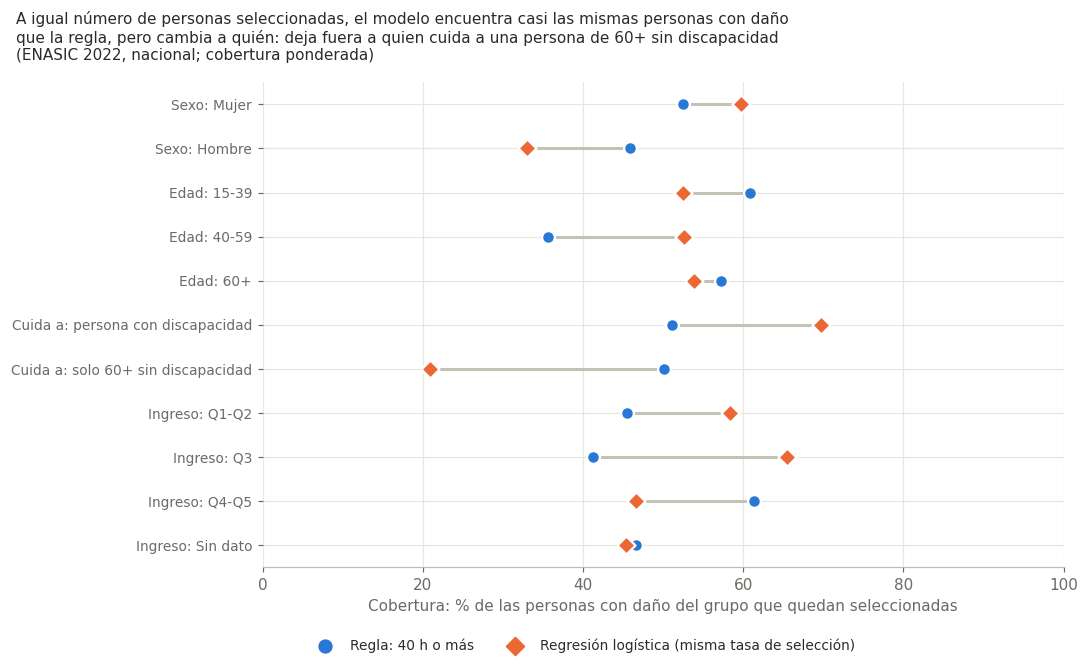

In [54]:
orden = [('SEXO', 'Mujer'), ('SEXO', 'Hombre'), ('EDAD', '15-39'), ('EDAD', '40-59'), ('EDAD', '60+'),
         ('TIPO', 'Cuida discapacidad'), ('TIPO', 'Solo 60+ sin discapacidad'),
         ('ING', 'Q1-Q2'), ('ING', 'Q3'), ('ING', 'Q4-Q5'), ('ING', 'Sin dato')]
piv = grp.set_index(['dimension', 'grupo', 'puntaje']).cobertura
fig, ax = plt.subplots(figsize=(10, 6.2))
ypos = np.arange(len(orden))[::-1]
for yy, (dim, g) in zip(ypos, orden):
    a, b = piv[(dim, g, 'Regla >= 40 h')], piv[(dim, g, 'Regresión logística')]
    ax.plot([a, b], [yy, yy], color='#c3c2b7', lw=2, zorder=1)
    ax.scatter(a, yy, s=70, color='#2a78d6', marker='o', zorder=2, edgecolor='white', linewidth=1.5)
    ax.scatter(b, yy, s=70, color='#eb6834', marker='D', zorder=2, edgecolor='white', linewidth=1.5)
ETQ = {'SEXO': 'Sexo', 'EDAD': 'Edad', 'TIPO': 'Cuida a', 'ING': 'Ingreso'}
ax.set_yticks(ypos, [f'{ETQ[dim]}: {g}'.replace('Cuida a: Cuida discapacidad', 'Cuida a: persona con discapacidad').replace('Cuida a: Solo 60+ sin discapacidad', 'Cuida a: solo 60+ sin discapacidad') for dim, g in orden], fontsize=9)
ax.set_xlabel('Cobertura: % de las personas con daño del grupo que quedan seleccionadas')
ax.set_xlim(0, 100); ax.grid(axis='x', color='#e8e7e1', lw=0.8); ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.scatter([], [], s=70, color='#2a78d6', marker='o', label='Regla: 40 h o más')
ax.scatter([], [], s=70, color='#eb6834', marker='D', label='Regresión logística (misma tasa de selección)')
ax.legend(loc='upper center', bbox_to_anchor=(0.4, -0.12), ncol=2, frameon=False, fontsize=9)
fig.suptitle('A igual número de personas seleccionadas, el modelo encuentra casi las mismas personas con daño\n'
             'que la regla, pero cambia a quién: deja fuera a quien cuida a una persona de 60+ sin discapacidad\n'
             '(ENASIC 2022, nacional; cobertura ponderada)', fontsize=10, x=0.02, ha='left')
plt.tight_layout(); plt.savefig(FIG / 'f10_cobertura_por_grupo_modelo.png', dpi=150); plt.show()

## 9. Guardar resultados

In [55]:
glob.assign(objetivo='DANO_ALGUNO').to_csv(OUT / '11_modelo_focalizacion_global.csv', index=False, encoding='utf-8-sig')
grp.assign(objetivo='DANO_ALGUNO').to_csv(OUT / '11_modelo_focalizacion_por_grupo.csv', index=False, encoding='utf-8-sig')
sens.assign(objetivo='DANO_SALUD_FISICA').to_csv(OUT / '11_modelo_focalizacion_sensibilidad.csv', index=False, encoding='utf-8-sig')
coef.rename('coef_estandarizado').to_csv(OUT / '11_modelo_coeficientes_logit.csv', encoding='utf-8-sig')
print('Guardados 4 archivos en resultados/ y la figura f10 en figuras/')

Guardados 4 archivos en resultados/ y la figura f10 en figuras/


## 10. Lectura

Todo es **nacional** y se lee de `resultados/11_modelo_focalizacion_*.csv`. Universo: 1,043 personas cuidadoras de una
persona con discapacidad o de 60+ en la muestra; 62.2% declara algún daño (ponderado).

**0. Validación.** Reproduce el 40.7% de personas que cuidan 40 h o más del notebook 07 y los cortes de quintil del 04.

**1. Con el objetivo principal (algún daño), el modelo no supera a la regla de forma demostrable.**
- El modelo ordena mejor: AUC ponderado 0.75 (regresión logística) y 0.74 (gradient boosting), contra 0.63 de la regla
  y 0.66 de las horas como puntaje continuo.
- Pero a la misma tasa de selección (40.7% de las personas cuidadoras), la regla encuentra al 50.8% de quienes declaran
  daño y la regresión logística al 53.0%. La diferencia, +2.2 pp, tiene un IC al 90% de −4.1 a 8.5: no excluye el cero.
  El gradient boosting: +3.4 pp (−2.4 a 9.2), tampoco.
- De las personas que selecciona la regla, 77.6% declara daño; de las que selecciona el modelo, 81.1%.
- **Conclusión para el programa:** para ofrecer relevo a quien declara algún daño, la regla "40 h o más" funciona casi
  igual que el modelo, se explica en una frase y solo requiere una pregunta. Es un resultado válido, no un fracaso.

**2. Con el objetivo estricto (salud física deteriorada, 23.5%), el modelo sí supera a la regla.**
- Cobertura: 57.0% la regla contra 69.7% la regresión logística (+12.7 pp, IC 90%: 2.5 a 22.9) y 71.1% el gradient
  boosting (+14.1 pp, IC 90%: 3.8 a 24.5). AUC 0.76 contra 0.61.
- Si el programa decide priorizar el daño más grave, el modelo agrega valor que la regla no da.

**3. El modelo no es neutral: cambia a quién se selecciona.** A igual número de personas seleccionadas (figura f10):
- Quienes cuidan solo a una persona de 60+ sin discapacidad pasan de 50.2% de cobertura con la regla a 20.9% con la
  regresión logística (30.1% con gradient boosting).
- Los hombres, de 45.8% a 32.9%; los hogares de los quintiles 4-5, de 61.4% a 46.7%.
- Ganan quienes cuidan a una persona con discapacidad (51.2% → 69.7%), las mujeres (52.5% → 59.7%), las personas de
  40-59 años (35.6% → 52.6%) y los quintiles 1-3.
- Elegir entre regla y modelo es entonces una **decisión de política**, no solo técnica: el modelo concentra el relevo
  donde el daño es más frecuente y deja con menos cobertura a quien cuida a una persona mayor sin discapacidad.

**4. Qué asocia el modelo con el daño** (regresión logística, coeficientes estandarizados; asociaciones, no causas):
más horas (+0.47), cuidar además a menores (+0.38), que le falte fuerza física (+0.34), requerir apoyo de otra persona
(+0.30), más tareas clínicas (+0.29), ser mujer (+0.22) y ayudar en más actividades básicas (+0.20). Más ingreso se
asocia con menos daño declarado (−0.21).

**Condiciones bajo las cuales el modelo deja de funcionar o no debe usarse:**
1. **Bloque "60+ sin discapacidad".** La ENASIC no pregunta ahí por actividades básicas ni tareas clínicas. El modelo
   tiene menos información sobre ese grupo y lo subselecciona. Usarlo sin corregir esto desplaza el programa contra
   ese grupo por una limitación del cuestionario, no necesariamente de la necesidad.
2. **Otra población.** Se entrenó con personas cuidadoras de todo el país. No está validado para la CDMX ni para la
   población de una institución específica (sesgo de quién llega a la institución). Antes de usarlo en el piloto hay
   que recalibrarlo o, al menos, comparar su selección contra la regla con datos de la propia institución.
3. **Daño autodeclarado.** El objetivo es lo que la persona declara, con el posible sesgo de deseabilidad social que
   señaló el notebook 07. El modelo aprende a predecir la declaración, no el daño medido.
4. **Muestra chica en algunos grupos.** Hombres con daño: 156 casos; quintil 3 con daño: 116. La cobertura por grupo
   tiene intervalos amplios (ver `11_modelo_focalizacion_por_grupo.csv`).
5. **No es causal.** El modelo no dice que el relevo reduzca el daño ni a quién le serviría más.

**Protección de datos.** Varios predictores son datos personales y algunos sensibles (dependencia de la persona
cuidada, tareas clínicas). Si el dictamen de Leyes restringe alguno, el modelo se reentrena sin él y se vuelve a
comparar contra la regla. La regla de horas es la opción con menor tratamiento de datos.

**Pendiente de doble revisión.**